# Directional brain–heart interplay (dBHI)

Guided workflow for **Figs. 4–5, Figs. S3–S7 and Tables S4–S6**.
Select **Python (dbh)** after the [environment setup](../README.md#setup), run the
cells in order and answer the prompts in step 1.

**What dBHI measures.** The synthetic-data-generation (SDG) framework
(Catrambone et al., 2019; Candia-Rivera et al., 2022; PySDG, Kristensen et al., 2026)
gives two directional indices at 4 Hz for every electrode and movie:

- **brain-to-heart (bth):** how strongly EEG band power modulates the LF- and
  HF-HRV oscillator amplitudes of an IPFM heartbeat model;
- **heart-to-brain (htb):** the exogenous HRV coefficient of a first-order ARX
  model of EEG band power.

**Data.** The supplied model arrays cover 148 children (50/49/49 by age group).
Step 1 chooses between analysing them and estimating the model again from cleaned
EEG and reviewed R peaks; step 4 chooses which arrays the three independent
analysis branches use, and each branch asks before it runs.

| Step | What it does | Output |
|---|---|---|
| 1 | Select the workflow, model cache and reuse policy | Run settings and one log |
| 2 · Model | Check the Python environment and the model inputs or supplied arrays | Validation summary |
| 3 · Model | Estimate or resume the SDG model (estimation workflow only) | Per-child model arrays |
| 4 · Group | Choose the model arrays (manuscript or your own estimates) and the reuse policy | Analysis settings |
| 5 · Temporal | Ask to run; emotion-minus-neutral time courses: 288 sign-flip cluster tests (`sub-047` neutral truncated) | Cluster tables |
| 6 · Temporal | Figures S3–S4 and Table S4 | PNG and CSV |
| 7 · Shared | Select high- and low-intensity epochs from the adult ratings | Epoch table, Figure S5 |
| 8 · Age | Ask to run; four ridge age models with label permutations | Model results |
| 9 · Age | Child-centred models and bootstrap Haufe patterns | Pattern tables |
| 10 · Age | Figure 4 and Table S5 | PNG and CSV |
| 11 · Intensity | Ask to run; high-minus-low intensity contrasts per electrode | 148 × 4 × 2 × 63 arrays |
| 12 · Intensity | 96 spatial cluster tests | Cluster tables and null distributions |
| 13 · Intensity | Figure 5, Figures S6–S7 and Table S6 | PNG and CSV |

**Model settings** (fixed; recorded in `outputs/manuscript/model/_manifest.json`):

| Setting | Value | Why |
|---|---|---|
| Window / output rate | 15 s, stepped at 0.25 s (4 Hz) | 4 Hz also sets the RR interpolation rate, so the HRV spectrum reaches 2 Hz; at 1 Hz the Nyquist limit (0.5 Hz) fell inside the children's HF band |
| EEG periodogram | 2 s, Hamming | 0.5-Hz resolution resolves the 1–4-Hz delta band |
| EEG bands | 1–4, 4–7, 7–12, 12–30 Hz | same as the band-power pipeline in `01_preprocessing/` |
| HRV bands | LF 0.04–0.15, HF 0.15–0.80 Hz | HF ceiling raised from the adult 0.40 Hz for children's faster respiration; same as the HRV pipeline |
| IPFM oscillator centres | 0.083 / 0.32 Hz | the cohort's LF/HF spectral centroids (RSA peak ≈ 0.32 Hz), not band midpoints |
| Smoothing / normalisation | 7.5-s moving average; min–max within each clip | the original model's conventions; indices express relative coupling |
| Transform | log10 per electrode before any averaging; htb floored at 3.4 × 10⁻⁴ first | both indices are strongly right-skewed ratios; the floor is the first percentile of positive htb values (`sdg/htb_floor.json`, fixed) |

Group analyses need all 148 children. A complete run of all three branches takes
about ten minutes; the longest steps (5, 8 and 9) report progress below their cells.

## 1. Select the workflow and paths

At each prompt, type a choice and press **Enter**. Enter alone selects the default.

**Workflow**

- **1 — analyse the supplied model arrays (default):** read the 148 per-child
  arrays in `outputs/manuscript/model/`.
- **2 — estimate the model:** run the SDG model from the cleaned EEG and reviewed
  R peaks (all participant-table IDs, or the included example `sub-001`).
  Estimates go to `outputs/batch/model/` (full cohort) or `outputs/demo/model/`
  (selected IDs); the supplied arrays are never replaced. If that folder already
  holds estimates, the prompt asks whether to keep them (estimating only missing
  children) or re-estimate; estimates made with different model code or packages
  can only be replaced.

Step 4 then chooses which arrays the group analyses use and whether to reuse saved
results. Each run writes one log to `05_dBHI/logs/`.

| Input (read only) | Analyse supplied arrays | Estimate the model |
|---|---|---|
| Participants | `00_data/participants.csv` | same |
| Movie intensity ratings | `00_data/events/Movies_rating_by_RA.csv` | same |
| Cleaned EEG, reviewed R peaks | not used | `01_preprocessing/outputs/manuscript/eeg/cleaned/`, `ecg/r_peaks/` (`sub-001`: `outputs/demo/`) |
| Model arrays | `05_dBHI/outputs/manuscript/model/` (148 × `{ID}_dbhi.npz`, `_manifest.json`; the neutral clip of `sub-047` is truncated, see step 5) | written to `outputs/batch/model/` (full cohort) or `outputs/demo/model/` (selected IDs), or a folder you type |
| Model completion report | `05_dBHI/outputs/manuscript/model_reports/run_status.json` | written next to the new model folder |

| Intermediate output | Location |
|---|---|
| Steps 2–3: input QC and model reports | `05_dBHI/outputs/manuscript/model_reports/`, or `outputs/batch/model_reports/` / `outputs/demo/model_reports/` for new estimates |
| Steps 5–6: temporal cluster tables | `05_dBHI/cache/time_resolved/` |
| Step 7: smoothed ratings and selected epochs | `05_dBHI/cache/intensity_contrast/` |
| Steps 8–9: features, predictions, nulls, Haufe patterns | `05_dBHI/cache/age_prediction/` |
| Steps 11–12: contrast arrays, spatial clusters, null distributions | `05_dBHI/cache/intensity_contrast/`, `topo_cluster/` |
| Final | `results/Main/` (Figs. 4–5), `results/SI/` (Figs. S3–S7, Tables S4–S6) |

In [3]:
from importlib import import_module, reload
from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

override = os.environ.get("DBHI_PROJECT_ROOT")
candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "05_dBHI/config/dbhi_config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository, or set DBHI_PROJECT_ROOT.")
DBHI = ROOT / "05_dBHI"
INFO_FILE = ROOT / "00_data/participants.csv"
RATINGS_FILE = ROOT / "00_data/events/Movies_rating_by_RA.csv"
OUTPUT_ROOT = Path(os.environ.get("DBHI_OUTPUT_ROOT", str(DBHI))).expanduser()
OUTPUT_ROOT = (OUTPUT_ROOT if OUTPUT_ROOT.is_absolute() else ROOT / OUTPUT_ROOT).resolve()
SUPPLIED_CACHE = DBHI / "outputs/manuscript/model"
NEUTRAL_SUBJECT = "sub-047"
N_JOBS = 4

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RunLog = reload(import_module("common.run_log")).RunLog
reload(import_module("common.cache_policy"))
settings = reload(import_module("05_dBHI.config.dbhi_config"))
helpers = reload(import_module("05_dBHI.config.notebook_helpers"))
cache_policy = reload(import_module("05_dBHI.config.cache_policy"))
display(HTML('<style id="dbh-notebook-style">' +
             (ROOT / "common/notebook_style.css").read_text(encoding="utf-8") + "</style>"))
LOG = RunLog(OUTPUT_ROOT / "logs", ROOT, title="dBHI", announce=False)
shown = LOG.display

WORKFLOW, MODEL_IDS, MODEL_CACHE = cache_policy.choose_workflow(ROOT, SUPPLIED_CACHE, log=LOG)
SUPPLIED_REPORTS = SUPPLIED_CACHE.with_name("model_reports")
MODEL_REPORTS = SUPPLIED_REPORTS if WORKFLOW == "analyse" else MODEL_CACHE.with_name(MODEL_CACHE.name + "_reports")
MODEL_NEUTRAL_FILE = MODEL_CACHE / f"{NEUTRAL_SUBJECT}_dbhi.npz"
MODEL_ARGS = ["--participants", INFO_FILE, "--cache-dir", MODEL_CACHE, "--reports-dir", MODEL_REPORTS]
for sid in MODEL_IDS or []:
    MODEL_ARGS += ["--subject", sid]
RUN_TEMPORAL = RUN_AGE = RUN_INTENSITY = False  # each branch asks in its first step


def run_script(script, args=()):
    # Run one analysis script as a subprocess; output streams here and into the run log.
    LOG.command([sys.executable, "-u", DBHI / script, "--output-root", OUTPUT_ROOT, *args])


def saved(files, label, inputs=(), status=None):
    return cache_policy.use_cached_results(files, recompute=RECOMPUTE, label=label, log=LOG,
                                           inputs=inputs, status=status)


n_arrays = len(list(MODEL_CACHE.glob("sub-*_dbhi.npz"))) if MODEL_CACHE.is_dir() else 0
if WORKFLOW == "analyse":
    LOG.write(f"\nWorkflow: analyse the supplied model arrays ({n_arrays} children)")
    inputs = [("Participants", INFO_FILE), ("Movie ratings", RATINGS_FILE),
              ("Model arrays", MODEL_CACHE), ("Model report", MODEL_REPORTS / "run_status.json")]
else:
    who = "all participant-table IDs" if MODEL_IDS is None else ", ".join(MODEL_IDS)
    LOG.write(f"\nWorkflow: estimate the SDG model for {who}")
    demo = MODEL_IDS is not None and all((ROOT / "01_preprocessing/outputs/demo/eeg/cleaned" / f"{s}_continuous_clean.mat").is_file() for s in MODEL_IDS)
    source = ROOT / ("01_preprocessing/outputs/demo" if demo else "01_preprocessing/outputs/manuscript")
    os.environ["DBHI_EEG_DIR"] = str(source / "eeg/cleaned")
    os.environ["DBHI_RPEAK_DIR"] = str(source / "ecg/r_peaks")
    inputs = [("Participants", INFO_FILE), ("Movie ratings", RATINGS_FILE),
              ("Cleaned EEG", source / "eeg/cleaned"), ("Reviewed R peaks", source / "ecg/r_peaks")]
outputs = [("Model arrays", MODEL_CACHE), ("Model reports", MODEL_REPORTS)] if WORKFLOW == "estimate" else []
print(f"\nWorkflow: {'analyse the supplied model arrays' if WORKFLOW == 'analyse' else 'estimate the SDG model'}"
      + (f" ({n_arrays} children)" if WORKFLOW == "analyse" else ""))
for heading, items in (("Inputs (read only)", inputs), ("Outputs", outputs)):
    if not items:
        continue
    print(heading)
    LOG.write(heading)
    for label, path in items:
        print(f"  {label:<20}{shown(path)}")
        LOG.write(f"  {label:<20}{shown(path)}")
print("Run log:", shown(LOG.path))

1 = analyse the supplied 148-child model arrays (default)
2 = estimate the SDG model from cleaned EEG and reviewed R peaks, then analyse


Type 1 or 2, then press Enter (Enter alone = 1):  2


Participants: Enter alone = every ID in the participant table (full cohort);
or type one ID for the included example (sub-001) or several IDs separated by commas.


Participant IDs (Enter alone = all):  sub-001


New estimates are written to 05_dBHI/outputs/demo/model (the supplied arrays in 05_dBHI/outputs/manuscript/model/ are never replaced).


Press Enter to use this folder, or type another folder:  


05_dBHI/outputs/demo/model already holds 1 valid estimate(s): sub-001
1 = keep them and estimate only missing children (default)
2 = re-estimate and replace them


Type 1 or 2, then press Enter (Enter alone = 1):  2



Workflow: estimate the SDG model
Inputs (read only)
  Participants        00_data/participants.csv
  Movie ratings       00_data/events/Movies_rating_by_RA.csv
  Cleaned EEG         01_preprocessing/outputs/demo/eeg/cleaned
  Reviewed R peaks    01_preprocessing/outputs/demo/ecg/r_peaks
Outputs
  Model arrays        05_dBHI/outputs/demo/model
  Model reports       05_dBHI/outputs/demo/model_reports
Run log: 05_dBHI/logs/20261030_225036.log


## 2. Check the Python environment and the model inputs

**Environment.** `check_setup.py --python-only` imports the pinned packages in a
fresh interpreter and records their versions in the log. An import failure stops here.

**Analyse workflow** — `analysis/inputs.py` validates the supplied arrays:

- exactly the 148 participant-table IDs, group sizes 50/49/49;
- saved model settings equal this analysis specification;
- every array's axes are the model's four EEG bands (delta, theta, alpha, beta, in
  that order), both HRV bands, a 4-Hz time axis and the same 63-channel order;
- the completion report carries the cache fingerprint and the array of `sub-047`
  records its truncated neutral clip.

A summary of the model settings is displayed. The EEG bands listed there are the
frequency ranges the SDG model integrates internally from its own periodograms;
the band-power files of `01_preprocessing/` are not used anywhere in dBHI.

**Estimate workflow** — the input preflight of `preparation/compute_dbhi.py` checks:

- EEG segmentation, channel order and agreement between EEG boundaries and ECG markers;
- R peaks inside each movie and enough of them for the 15-s windows;
- an RR gap above 2 s is flagged as a warning in `input_qc.csv` (the 19-s neutral
  gap of `sub-047` is one; step 5 handles it). Hard failures stop the batch.

In [5]:
with LOG.step("Environment and model inputs"):
    LOG.command([sys.executable, ROOT / "check_setup.py", "--python-only", "--quiet"])
    info = pd.read_csv(INFO_FILE, dtype={"ID": str})
    groups = {g: int(info.Age_group.isin(a).sum()) for g, a in settings.GROUPS.items()}
    if WORKFLOW == "analyse":
        run_script("analysis/inputs.py", ["--participants", INFO_FILE, "--cache-dir", MODEL_CACHE,
                                          "--reports-dir", MODEL_REPORTS, "--neutral-subject", NEUTRAL_SUBJECT, "--temporal"])
        manifest = json.loads((MODEL_CACHE / "_manifest.json").read_text())
        config = manifest["config"]
        summary = pd.DataFrame([
            {"Setting": "Participants", "Value": f"{len(info)} ({' / '.join(str(n) for n in groups.values())} by age group)"},
            {"Setting": "Model arrays", "Value": f"{n_arrays} files in {shown(MODEL_CACHE)}"},
            {"Setting": "EEG bands integrated by the model (Hz)", "Value": "; ".join(f"{b} {lo}–{hi}" for b, (lo, hi) in config["flims_eeg"].items())},
            {"Setting": "HRV bands integrated by the model (Hz)", "Value": "; ".join(f"{b} {lo}–{hi}" for b, (lo, hi) in manifest["hrv_bands_hz"].items())},
            {"Setting": "IPFM oscillator centres (Hz)", "Value": "; ".join(f"{b} {v}" for b, v in manifest["ipfm_centers_hz"].items())},
            {"Setting": "Window / output rate / EEG periodogram", "Value": f"{config['window']} s / {config['fs_bhi']} Hz / {config['tfr_eeg_win']} s"},
            {"Setting": "Normalisation", "Value": manifest["normalization"].replace("_", " ")},
            {"Setting": "Cache fingerprint", "Value": json.loads((MODEL_REPORTS / "run_status.json").read_text())["fingerprint"][:16] + "…"},
        ])
        display(summary.style.hide(axis="index"))
        LOG.write(f"Validated {n_arrays} model arrays; groups {groups}")
    else:
        run_script("preparation/compute_dbhi.py", MODEL_ARGS + ["--check-only"])
        qc = helpers.show_table(MODEL_REPORTS / "input_qc.csv",
                                columns=["subject", "condition", "status", "duration_s", "rpeak_count", "max_rr_s",
                                         "rr_over_2s", "detail"],
                                formats={"duration_s": "{:.1f}", "max_rr_s": "{:.2f}"},
                                title="Input QC (one row per movie clip)")
        LOG.write(f"Input QC: {len(qc)} clips; {int((qc.status != 'ok').sum())} flagged")

Python 3.12.7: /opt/anaconda3/envs/dbh/bin/python
[OK] numpy 2.2.6; scipy 1.16.3; pandas 2.3.3; matplotlib 3.10.8; sklearn 1.8.0; statsmodels 0.14.6; h5py 3.16.0; joblib 1.4.2; numba 0.61.2; llvmlite 0.44.0; tqdm 4.66.5; mne 1.11.0; neurokit2 0.2.13; IPython 9.17.1; ipykernel 6.28.0; jupyterlab 4.2.5; nbformat 5.10.4; tkinter available
Input checks passed for 1 participant(s); 0 flagged clip(s).


**Input QC (one row per movie clip)**

subject,condition,status,duration_s,rpeak_count,max_rr_s,rr_over_2s,detail
sub-001,fear,ok,186.9,274,0.86,0,nan
sub-001,neutral,ok,238.5,359,0.84,0,nan
sub-001,happy,ok,189.9,260,0.88,0,nan


## 3. Estimate or resume the SDG model

Estimation workflow only. `sdg/pipeline.py` runs the unchanged model for every
selected child and movie:

1. EEG band power at each electrode from 2-s periodograms;
2. HRV LF/HF power from the 4-Hz RR series;
3. the IPFM brain-to-heart gain and the ARX heart-to-brain coefficient in 15-s
   windows, assigned to the window centre.

**Caching**

- Each child's arrays are written atomically to `{ID}_dbhi.npz` with the run
  fingerprint (model source hashes, settings, package versions).
- A rerun resumes valid caches and recomputes failed ones.
- A cache with a different fingerprint is refused, never overwritten.
- When `sub-047` is among the estimated children, its neutral clip is then
  truncated in place (see step 5).

One child takes two to three minutes per worker; `N_JOBS` workers run in parallel.

**Reports** (`model_reports/`): `input_qc.csv` (one row per movie clip) and
`run_status.json` (state, counts, failed IDs, seconds per child, run fingerprint).
Per-array QC lives inside each `{ID}_dbhi.npz`. Console lines go to the run log.

In [7]:
with LOG.step("SDG model"):
    if WORKFLOW == "estimate":
        run_script("preparation/compute_dbhi.py", MODEL_ARGS + ["--n-jobs", str(N_JOBS)])
        if MODEL_NEUTRAL_FILE.is_file():
            run_script("preparation/recompute_neutral_dbhi.py",
                       ["--cache-dir", MODEL_CACHE, "--reports-dir", MODEL_REPORTS, "--neutral-subject", NEUTRAL_SUBJECT])
        status = json.loads((MODEL_REPORTS / "run_status.json").read_text())
        LOG.write(f"Model run {status.get('state')}: estimated {status.get('estimated', 0)}, resumed {status.get('resumed', 0)}, failed {status.get('failed', 0)} of {status.get('expected')}")
    else:
        print("Using the supplied model arrays; nothing to estimate.")

[1/1] sub-001: ok 28.7s 
Complete: 1 valid model files (1 estimated now, 0 resumed, in 05_dBHI/outputs/demo/model).


## 4. Choose the model arrays and the reuse policy for the group analyses

Two prompts:

**Model arrays**

- **1 — manuscript arrays (default):** the supplied 148-child estimates in
  `outputs/manuscript/model/`.
- **2 — your own estimates:** the folder written in step 3 (or `outputs/batch/model/`).
  Offered only when it holds all 148 children; a partial set such as the `sub-001`
  example is reported and cannot be used, so choose 1.

**Saved results**

- **1 — reuse complete saved results (default):** the supplied `cache/` holds the
  results of the submitted analysis computed from the manuscript arrays, so this
  reproduces the manuscript output; missing, incomplete or outdated results are
  recomputed anyway.
- **2 — recompute and replace** everything. Results computed from your own
  estimates replace the saved ones in `cache/` and `results/`; set `DBHI_OUTPUT_ROOT`
  before opening the notebook to keep them separate.

Each of the three branches then asks whether to run (steps 5, 8 and 11).

In [9]:
BATCH_CACHE = MODEL_CACHE if WORKFLOW == "estimate" else DBHI / "outputs/batch/model"
SOURCE = cache_policy.choose_model_source(SUPPLIED_CACHE, BATCH_CACHE, len(pd.read_csv(INFO_FILE, dtype={"ID": str})),
                                          root=ROOT, log=LOG)
CACHE_DIR = SUPPLIED_CACHE if SOURCE == "manuscript" else BATCH_CACHE
REPORT_DIR = SUPPLIED_REPORTS if SOURCE == "manuscript" else BATCH_CACHE.with_name(BATCH_CACHE.name + "_reports")
RECOMPUTE = cache_policy.choose_recompute()
LOG.write("Statistics: recompute" if RECOMPUTE else "Statistics: reuse complete saved results")

PATHS = settings.Paths(output_root=OUTPUT_ROOT, participants=INFO_FILE, ratings=RATINGS_FILE,
                       cache=CACHE_DIR, neutral_subject=NEUTRAL_SUBJECT, reports_dir=REPORT_DIR)
NEUTRAL_FILE = PATHS.neutral_file
MANIFEST_FILE = CACHE_DIR / "_manifest.json"
CACHE_ARGS = ["--participants", INFO_FILE, "--cache-dir", CACHE_DIR]
TEMPORAL_ARGS = CACHE_ARGS + ["--ratings", RATINGS_FILE, "--reports-dir", REPORT_DIR,
                              "--neutral-subject", NEUTRAL_SUBJECT]
print("\nOutputs")
for label, path in (("Temporal results", PATHS.time_results), ("Intensity results", PATHS.intensity_results),
                    ("Age results", PATHS.age_results), ("Figures and tables", PATHS.publication)):
    print(f"  {label:<20}{shown(path)}")
    LOG.write(f"  {label:<20}{shown(path)}")

Model arrays for the group analyses (steps 5-13)
1 = manuscript arrays, 05_dBHI/outputs/manuscript/model (148/148 children) (default)
2 = your own estimates, 05_dBHI/outputs/demo/model (1/148 children) — incomplete, cannot be used; choose 1


Type 1 or 2, then press Enter (Enter alone = 1):  2


Only 1 of 148 children are estimated; the group analyses need all 148. Choose 1 for the manuscript arrays.


Type 1 or 2, then press Enter (Enter alone = 1):  1


Group analyses use the manuscript model arrays: 05_dBHI/outputs/manuscript/model
Saved results of steps 5-13 (statistics, tables and figures)
1 = use complete saved results; compute missing or outdated steps (default)
2 = recompute and replace saved results and figures
Choose 2 after changing the model arrays, the participant table or the ratings.


Type 1 or 2, then press Enter (Enter alone = 1):  2



Outputs
  Temporal results    05_dBHI/cache/time_resolved
  Intensity results   05_dBHI/cache/intensity_contrast
  Age results         05_dBHI/cache/age_prediction
  Figures and tables  results


## 5. Temporal branch: emotion-minus-neutral cluster tests

The first prompt asks whether to run this branch (steps 5–6).

**Per child**

- Average the per-electrode log10 index over each region (`REGIONS` in
  `config/dbhi_config.py`: the frontal/central/posterior sets of the HEP analysis).
- Subtract the temporal mean of the neutral movie from the fearful and happy time
  courses.
- Align children on their common 4-Hz grid; nonfinite children are dropped per
  series and counted in the sample-count tables.

**`sub-047`.** Its neutral clip has a 19-s stretch without detected R peaks
(159.3–178.5 s), which makes the SDG neutral baseline unusable. The supplied array
holds neutral recomputed on 0–159.342 s with identical settings
(`preparation/recompute_neutral_dbhi.py`); fearful/happy are unchanged and the array
records the segment used. Only this branch uses the neutral clip.

**Test** (one-sample sign-flip cluster test within each age group)

| Setting | Value |
|---|---|
| Cluster-forming threshold | two-sided p < .05 |
| Minimum cluster length | 20 samples = **5 s** (the 15-s windows and 7.5-s smoothing make neighbouring samples strongly dependent) |
| Cluster mass | summed t |
| Permutations | **10,000 sign flips**, seed 0; p = (1 + exceedances) / 10,001 |
| Series | 288 = 2 directions × 2 HRV bands × 4 EEG bands × 3 regions × 2 movies × 3 groups |
| Correction | within each series only |

Progress appears per EEG band (about one minute per band). The summary and the
significant clusters are displayed.

| Intermediate file under `05_dBHI/cache/time_resolved/` | Contents |
|---|---|
| `included_subjects.csv` | 148 IDs with age group |
| `dBHI_{band}_clusters.csv` | every candidate cluster with mass, p and significance |
| `dBHI_{band}_sample_counts.csv` | children used per series and the common time range |
| `analysis_summary.csv`, `analysis_status.json`, `analysis_parameters.json` | per-band counts, completion state, settings and input hashes |

In [11]:
with LOG.step("Temporal clusters"):
    RUN_TEMPORAL = cache_policy.choose_branch("temporal", "5-6", log=LOG)
    if not RUN_TEMPORAL:
        print("Skipped: temporal branch not selected.")
    else:
        with np.load(NEUTRAL_FILE, allow_pickle=False) as array:
            clip = next(c for c in json.loads(str(array["_qc_json"].item()))["clips"] if c["condition"] == "neutral")
        if "segment_used_s" not in clip:
            run_script("preparation/recompute_neutral_dbhi.py",
                       ["--cache-dir", CACHE_DIR, "--reports-dir", REPORT_DIR, "--neutral-subject", NEUTRAL_SUBJECT])
            with np.load(NEUTRAL_FILE, allow_pickle=False) as array:
                clip = next(c for c in json.loads(str(array["_qc_json"].item()))["clips"] if c["condition"] == "neutral")
        segment = clip["segment_used_s"]
        print(f"{NEUTRAL_SUBJECT}: neutral clip truncated to {segment[0]:.0f}-{segment[1]:.3f} s "
              f"({clip['rpeak_count_used']} R peaks); fearful/happy unchanged.")
        LOG.write(f"{NEUTRAL_SUBJECT}: neutral truncated to {segment[0]:.0f}-{segment[1]:.3f} s")
        temporal_files = [PATHS.time_results / "included_subjects.csv", PATHS.time_results / "analysis_summary.csv",
                          PATHS.time_results / "analysis_parameters.json"]
        temporal_files += [PATHS.time_results / f"dBHI_{b}_{kind}.csv" for b in settings.BANDS for kind in ("clusters", "sample_counts")]
        if not saved(temporal_files, "Temporal clusters", inputs=[INFO_FILE, MANIFEST_FILE, NEUTRAL_FILE],
                     status=PATHS.time_results / "analysis_status.json"):
            run_script("analysis/analyze_dbhi_timecourses.py", TEMPORAL_ARGS)
        temporal_summary = helpers.show_table(PATHS.time_results / "analysis_summary.csv", title="Clusters per EEG band")
        temporal_clusters = pd.concat([pd.read_csv(PATHS.time_results / f"dBHI_{b}_clusters.csv").assign(band=b)
                                       for b in settings.BANDS], ignore_index=True)
        significant_temporal = temporal_clusters.loc[temporal_clusters.significant]
        print(f"Significant clusters: {len(significant_temporal)} / {len(temporal_clusters)} candidates in 288 series")
        display(significant_temporal[["band", "region", "emotion", "direction", "hrv", "group", "n", "start_s", "stop_s", "t_mass", "p"]]
                .sort_values(["direction", "band", "region", "emotion", "group", "start_s"])
                .style.hide(axis="index").format({"start_s": "{:.2f}", "stop_s": "{:.2f}", "t_mass": "{:.1f}", "p": "{:.4f}"}))
        LOG.write(f"Temporal clusters: {len(significant_temporal)} significant of {len(temporal_clusters)} candidates")

Run the temporal branch (steps 5-6)?
1 = yes (default)
2 = skip


Type 1 or 2, then press Enter (Enter alone = 1):  1


sub-047: neutral clip truncated to 0-159.342 s (225 R peaks); fearful/happy unchanged.
Temporal clusters: recomputing and replacing saved results.
                 n
analysis_group    
5-6 yrs         50
7-8 yrs         49
9-10 yrs        49
=== band: delta
=== band: theta
=== band: alpha
=== band: beta
    band  candidate_clusters  significant_clusters  series_tested
0  delta                 139                    73             72
1  theta                 151                    81             72
2  alpha                 183                    79             72
3   beta                 147                    76             72
Results: 05_dBHI/cache/time_resolved


**Clusters per EEG band**

band,candidate_clusters,significant_clusters,series_tested
delta,139,73,72
theta,151,81,72
alpha,183,79,72
beta,147,76,72


Significant clusters: 309 / 620 candidates in 288 series


band,region,emotion,direction,hrv,group,n,start_s,stop_s,t_mass,p
alpha,Central,fear,bth,LF,5-6 yrs,50,10.00,39.75,-491.4,0.0040
alpha,Central,fear,bth,HF,5-6 yrs,50,27.25,52.50,-312.5,0.0190
alpha,Central,fear,bth,LF,5-6 yrs,50,49.25,85.50,-505.5,0.0036
alpha,Central,fear,bth,LF,5-6 yrs,50,95.25,132.25,-511.2,0.0034
alpha,Central,fear,bth,HF,5-6 yrs,50,123.75,143.25,-232.6,0.0440
alpha,Central,fear,bth,LF,5-6 yrs,50,144.25,162.25,-248.0,0.0304
alpha,Central,fear,bth,LF,7-8 yrs,49,14.00,34.00,-219.3,0.0491
alpha,Central,fear,bth,HF,7-8 yrs,49,25.50,80.75,-692.8,0.0022
alpha,Central,fear,bth,LF,7-8 yrs,49,53.00,93.50,-532.6,0.0035
alpha,Central,fear,bth,LF,7-8 yrs,49,98.75,130.00,-350.8,0.0155


## 6. Temporal branch: Figures S3–S4 and Table S4

- **Figures S3 (fearful) and S4 (happy):** group-median frontal time courses of the
  delta-band indices with the adult intensity rating, plus rasters of every
  significant cluster for all bands and regions.
- **Table S4:** number and total duration of significant clusters per direction,
  HRV band, EEG band, region, movie and age group.

Both read the saved cluster tables; the figures also reread the model arrays.

| Final output | Location |
|---|---|
| `Figure_S3_dbhi_fear.png`, `Figure_S4_dbhi_happy.png` | `results/SI/` |
| `Table_S4_temporal_clusters.csv` | `results/SI/` |
| `temporal_clusters_significant.csv`, `temporal_clusters_long.csv`, `temporal_cluster_totals.csv` | `05_dBHI/cache/time_resolved/` |

Figures S3-S4 and Table S4: recomputing and replacing saved results.
Saved: results/SI/Figure_S3_dbhi_fear.png
Saved: results/SI/Figure_S4_dbhi_happy.png
n per group: {'5-6 yrs': 50, '7-8 yrs': 49, '9-10 yrs': 49}
n significant clusters: 309  sign by direction: {'bth': '0+/186-', 'htb': '123+/0-'}
n per group: {'5-6 yrs': array([50]), '7-8 yrs': array([49]), '9-10 yrs': array([49])}
  direction group   k  total_s
0       bth   5-6  97  5601.75
1       bth   7-8  80  6059.50
2       bth  9-10   9   263.75
3       htb   5-6  47  1731.75
4       htb   7-8  74  5246.75
5       htb  9-10   2    63.50


**Table S4. Significant temporal clusters: count (total duration)**

Direction,HRV band,EEG band,Region,Fearful 5-6,Fearful 7-8,Fearful 9-10,Happy 5-6,Happy 7-8,Happy 9-10
Heart→Brain,LF,delta,Frontal,1 (40 s),1 (154 s),—,2 (49 s),1 (149 s),—
Heart→Brain,LF,delta,Central,2 (74 s),1 (158 s),—,2 (60 s),1 (151 s),—
Heart→Brain,LF,delta,Posterior,2 (100 s),1 (162 s),—,1 (103 s),1 (150 s),—
Heart→Brain,LF,theta,Frontal,1 (41 s),2 (73 s),—,—,2 (107 s),—
Heart→Brain,LF,theta,Central,1 (39 s),1 (156 s),—,1 (28 s),2 (104 s),—
Heart→Brain,LF,theta,Posterior,2 (64 s),1 (159 s),—,2 (72 s),1 (146 s),—
Heart→Brain,LF,alpha,Frontal,1 (36 s),1 (30 s),—,—,2 (63 s),—
Heart→Brain,LF,alpha,Central,1 (34 s),2 (55 s),—,—,1 (58 s),—
Heart→Brain,LF,alpha,Posterior,1 (38 s),1 (155 s),2 (64 s),1 (51 s),3 (128 s),—
Heart→Brain,LF,beta,Frontal,1 (33 s),3 (100 s),—,—,2 (58 s),—


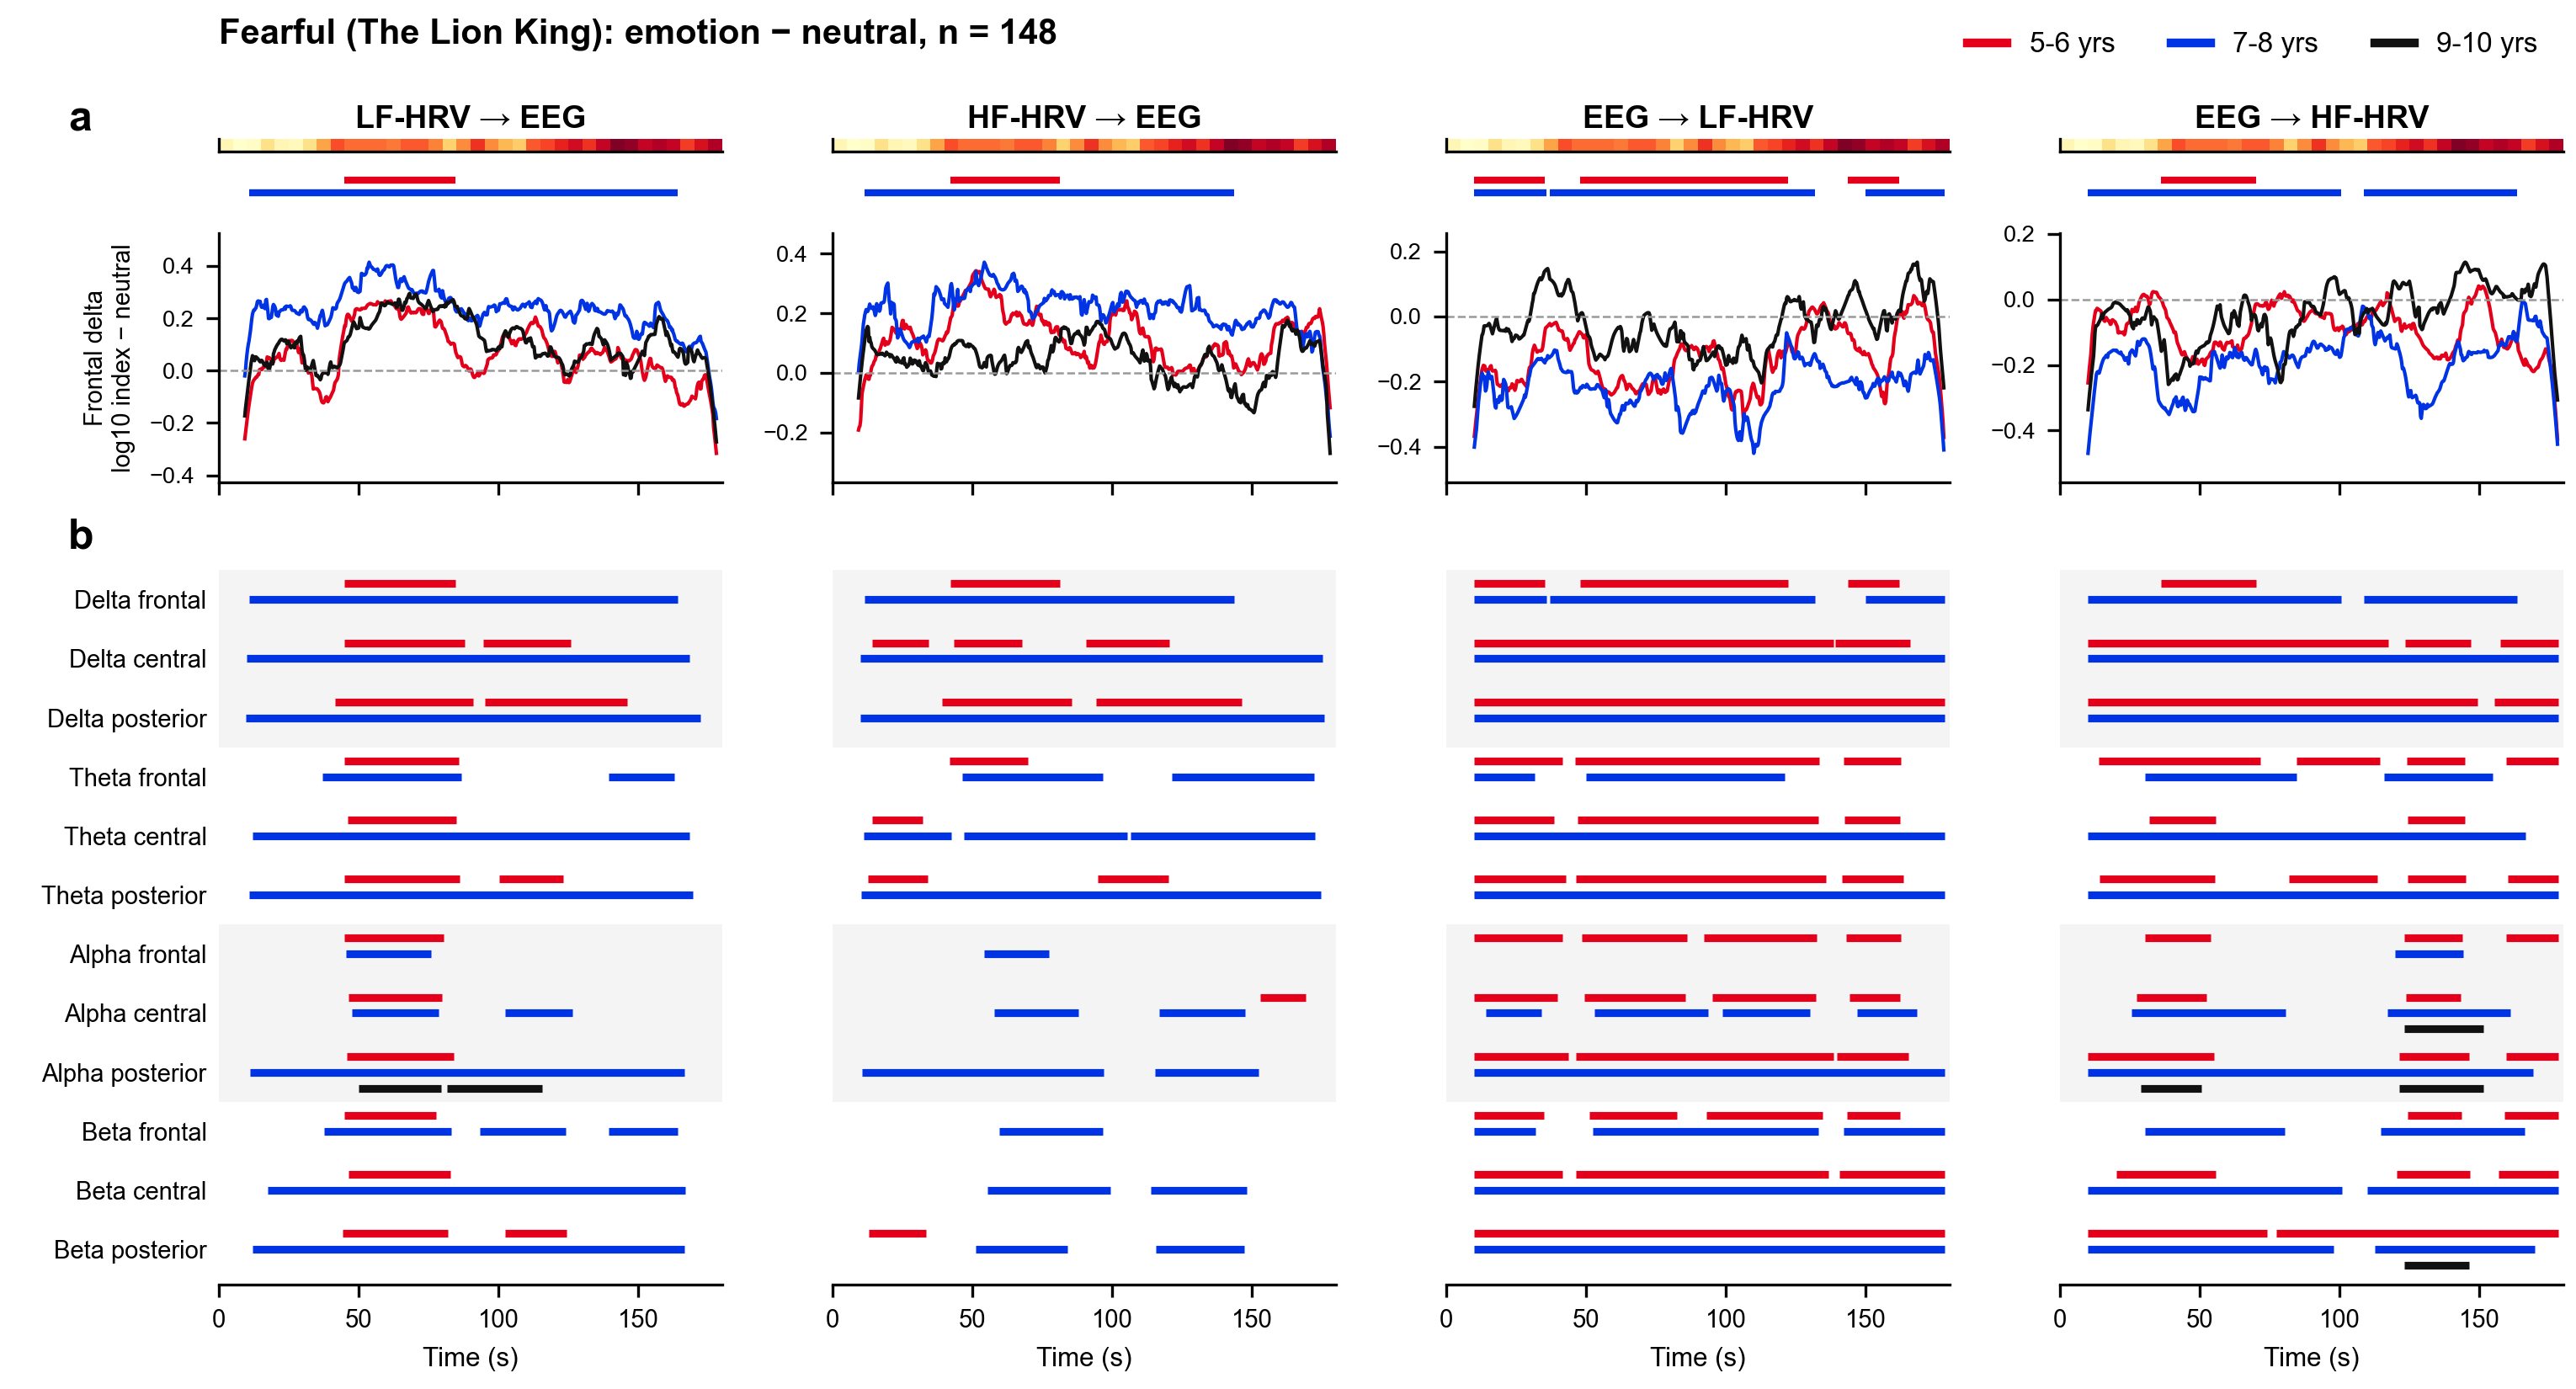

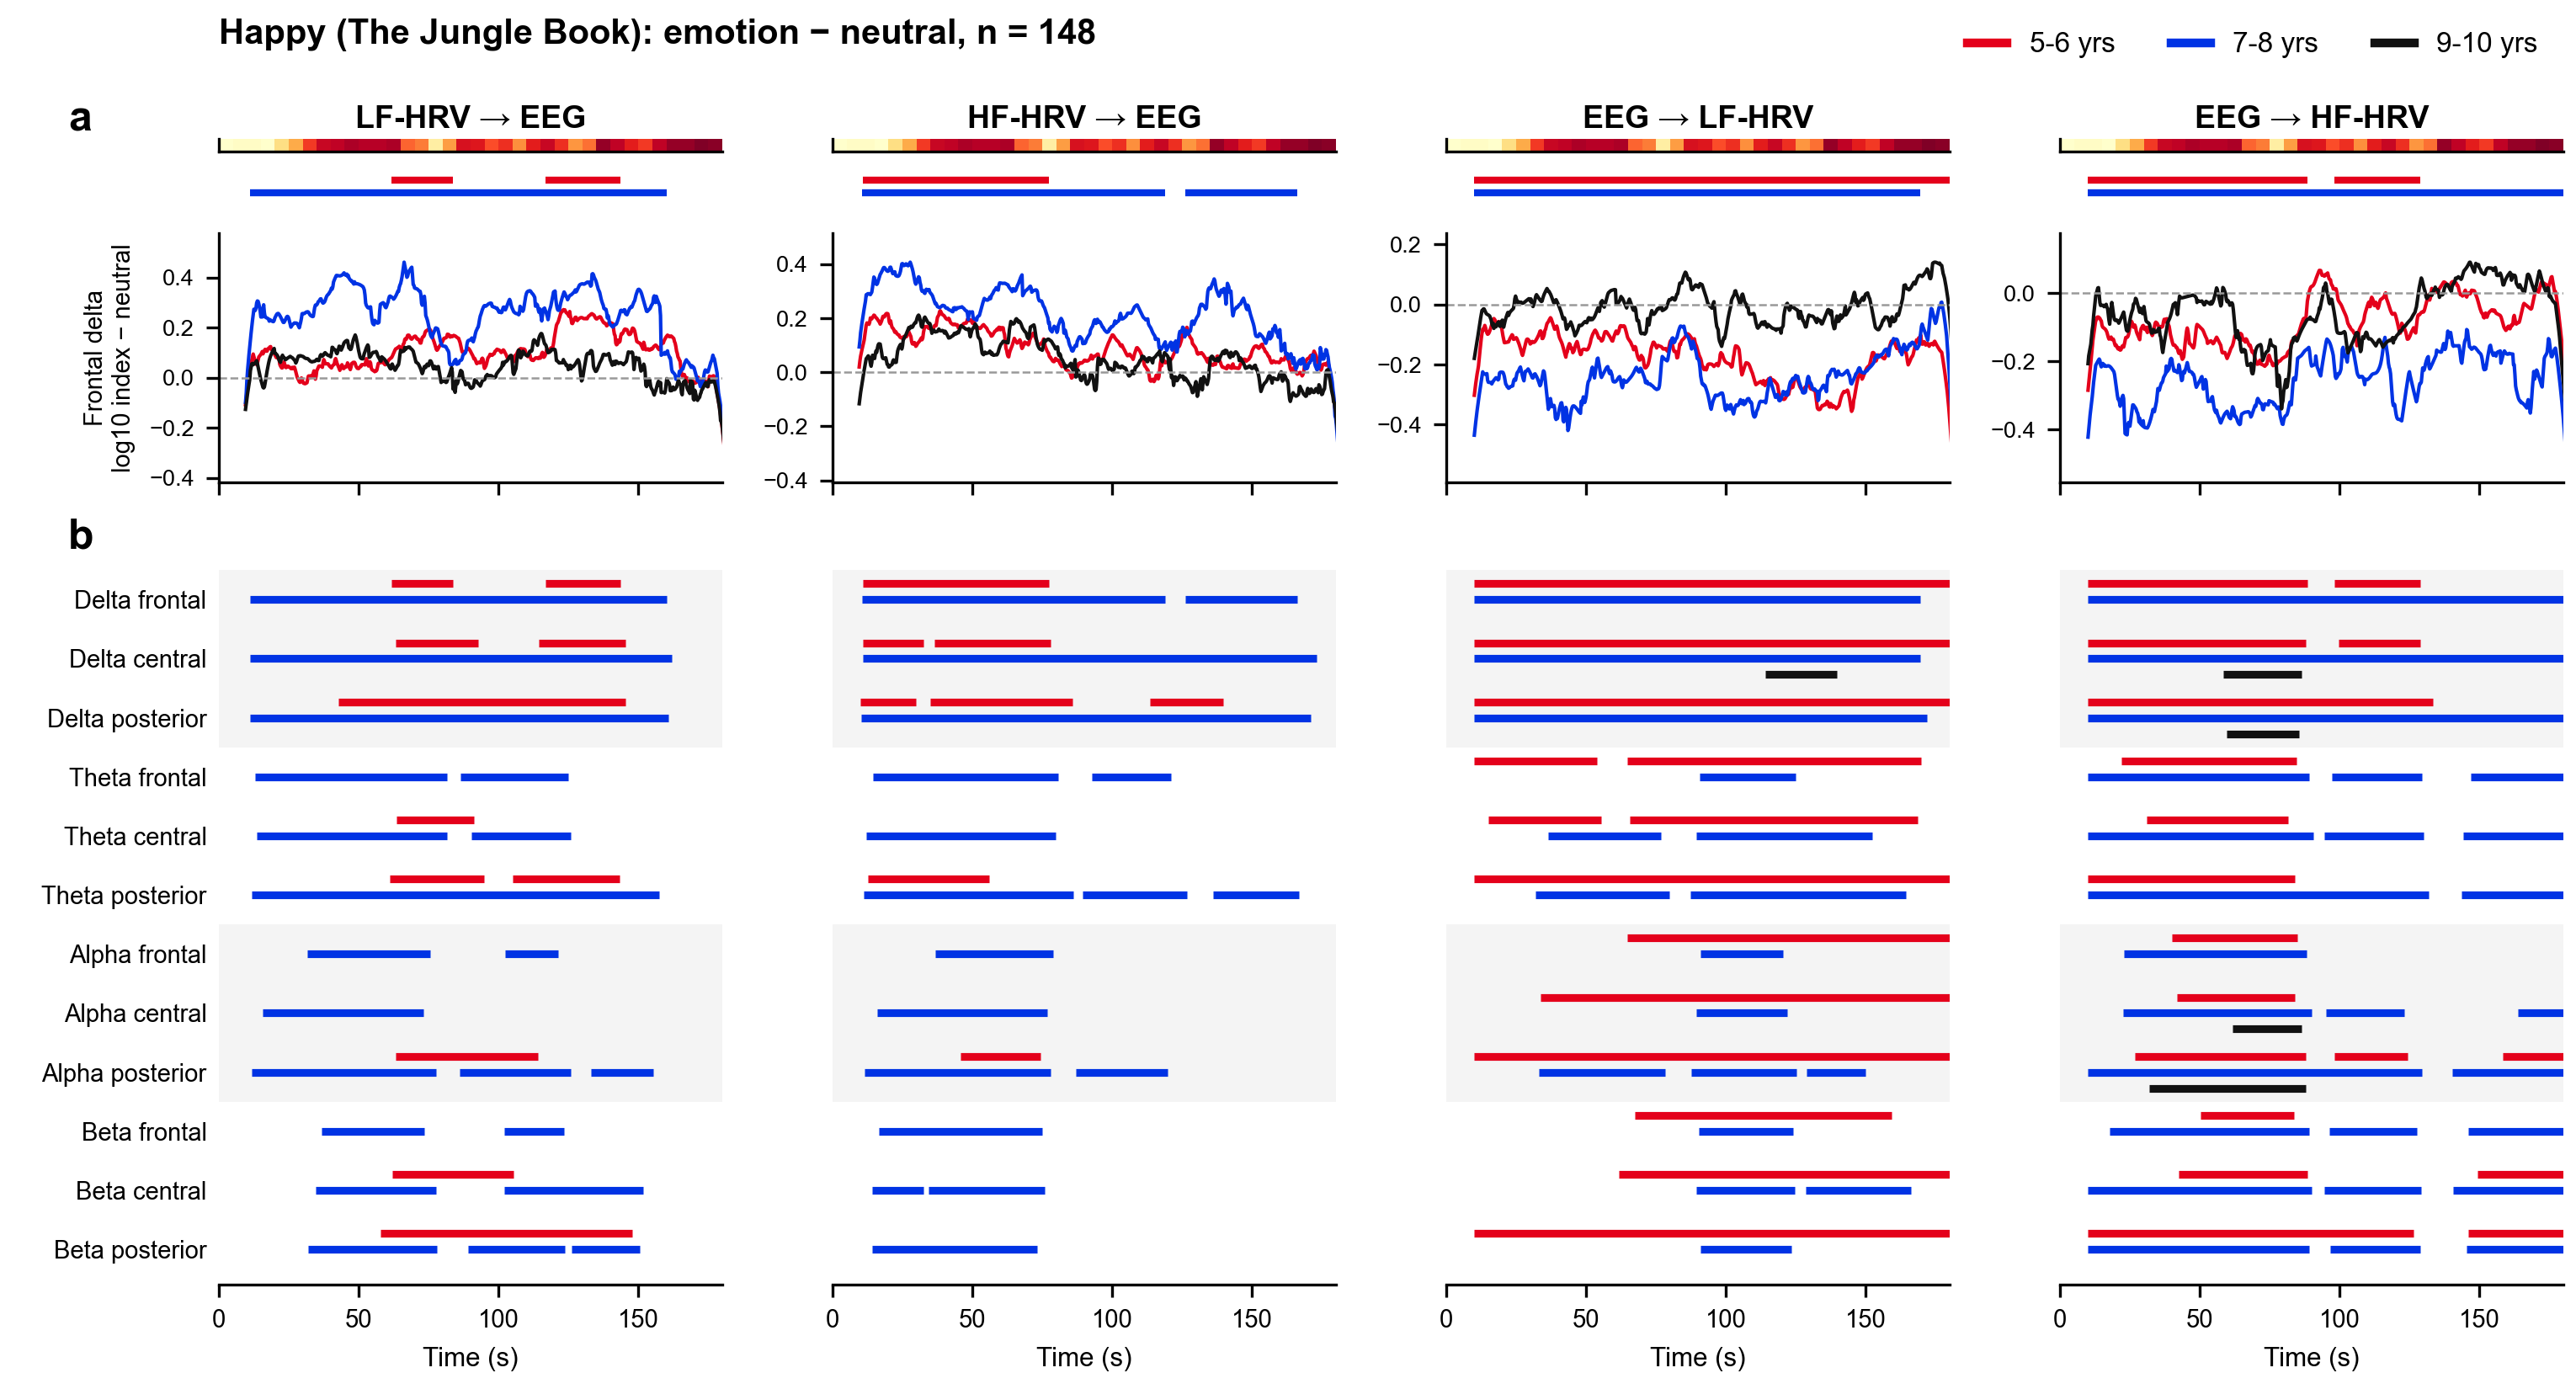

In [13]:
with LOG.step("Figures S3-S4 and Table S4"):
    if not RUN_TEMPORAL:
        print("Skipped: temporal branch not selected in step 5.")
    else:
        figures_s3_s4 = [PATHS.supplementary / "Figure_S3_dbhi_fear.png", PATHS.supplementary / "Figure_S4_dbhi_happy.png"]
        table_s4 = PATHS.supplementary / "Table_S4_temporal_clusters.csv"
        cluster_inputs = [PATHS.time_results / f"dBHI_{b}_clusters.csv" for b in settings.BANDS]
        if not saved(figures_s3_s4 + [table_s4, PATHS.time_results / "temporal_clusters_significant.csv"],
                     "Figures S3-S4 and Table S4", inputs=cluster_inputs + [NEUTRAL_FILE]):
            run_script("plotting/plot_figures_s3_s4_dbhi_timecourses.py", TEMPORAL_ARGS)
            run_script("analysis/export_table_s4_temporal_clusters.py")
        helpers.show_table(table_s4, title="Table S4. Significant temporal clusters: count (total duration)")
        for figure in figures_s3_s4:
            helpers.show_figure(figure, width=1000)
        LOG.write(f"Table S4 and Figures S3-S4: {shown(PATHS.supplementary)}")

## 7. Select high- and low-intensity epochs (Figure S5)

Shared by the age and intensity branches. Six adult raters scored the fearful and
happy movies every 5 s; `00_data/events/Movies_rating_by_RA.csv` holds their 1-Hz mean.

| Setting | Value | Why |
|---|---|---|
| Smoothing | 15-s forward window for every integer start 3–163 s | same length as the SDG estimation window |
| Selection | the 48 highest and 48 lowest windows per movie | 30% of the 161 windows; ties prefer the earlier time |
| Alignment | add 7.5 s to each window start | converts the rating-window start to the SDG window centre |
| Epoch | one second of the 4-Hz index (4 samples) per selected window | no minimum-run filter: selected seconds need not be contiguous |

The selection table and Figure S5 are displayed. Reused when the saved selection is
newer than the ratings file.

| Intermediate file under `05_dBHI/cache/intensity_contrast/` | Contents |
|---|---|
| `smoothed_intensity.csv` | 15-s window means for every start second |
| `ra_selected_epochs.csv` | 192 rows: movie, tail, rating-window start, epoch start/stop, score |
| `analysis_parameters.json` | window, shift, seconds per tail, tie rule |

**Final figure:** `results/SI/Figure_S5_intensity_epochs.png`.

Intensity epochs: recomputing and replacing saved results.
Selection: 05_dBHI/cache/intensity_contrast
Saved: results/SI/Figure_S5_intensity_epochs.png


emotion,level,epochs,first_start_s,last_start_s,mean_rating
fear,bottom30,48,10.5,109.5,3.11
fear,top30,48,123.5,170.5,7.71
happy,bottom30,48,10.5,129.5,2.83
happy,top30,48,38.5,170.5,6.43


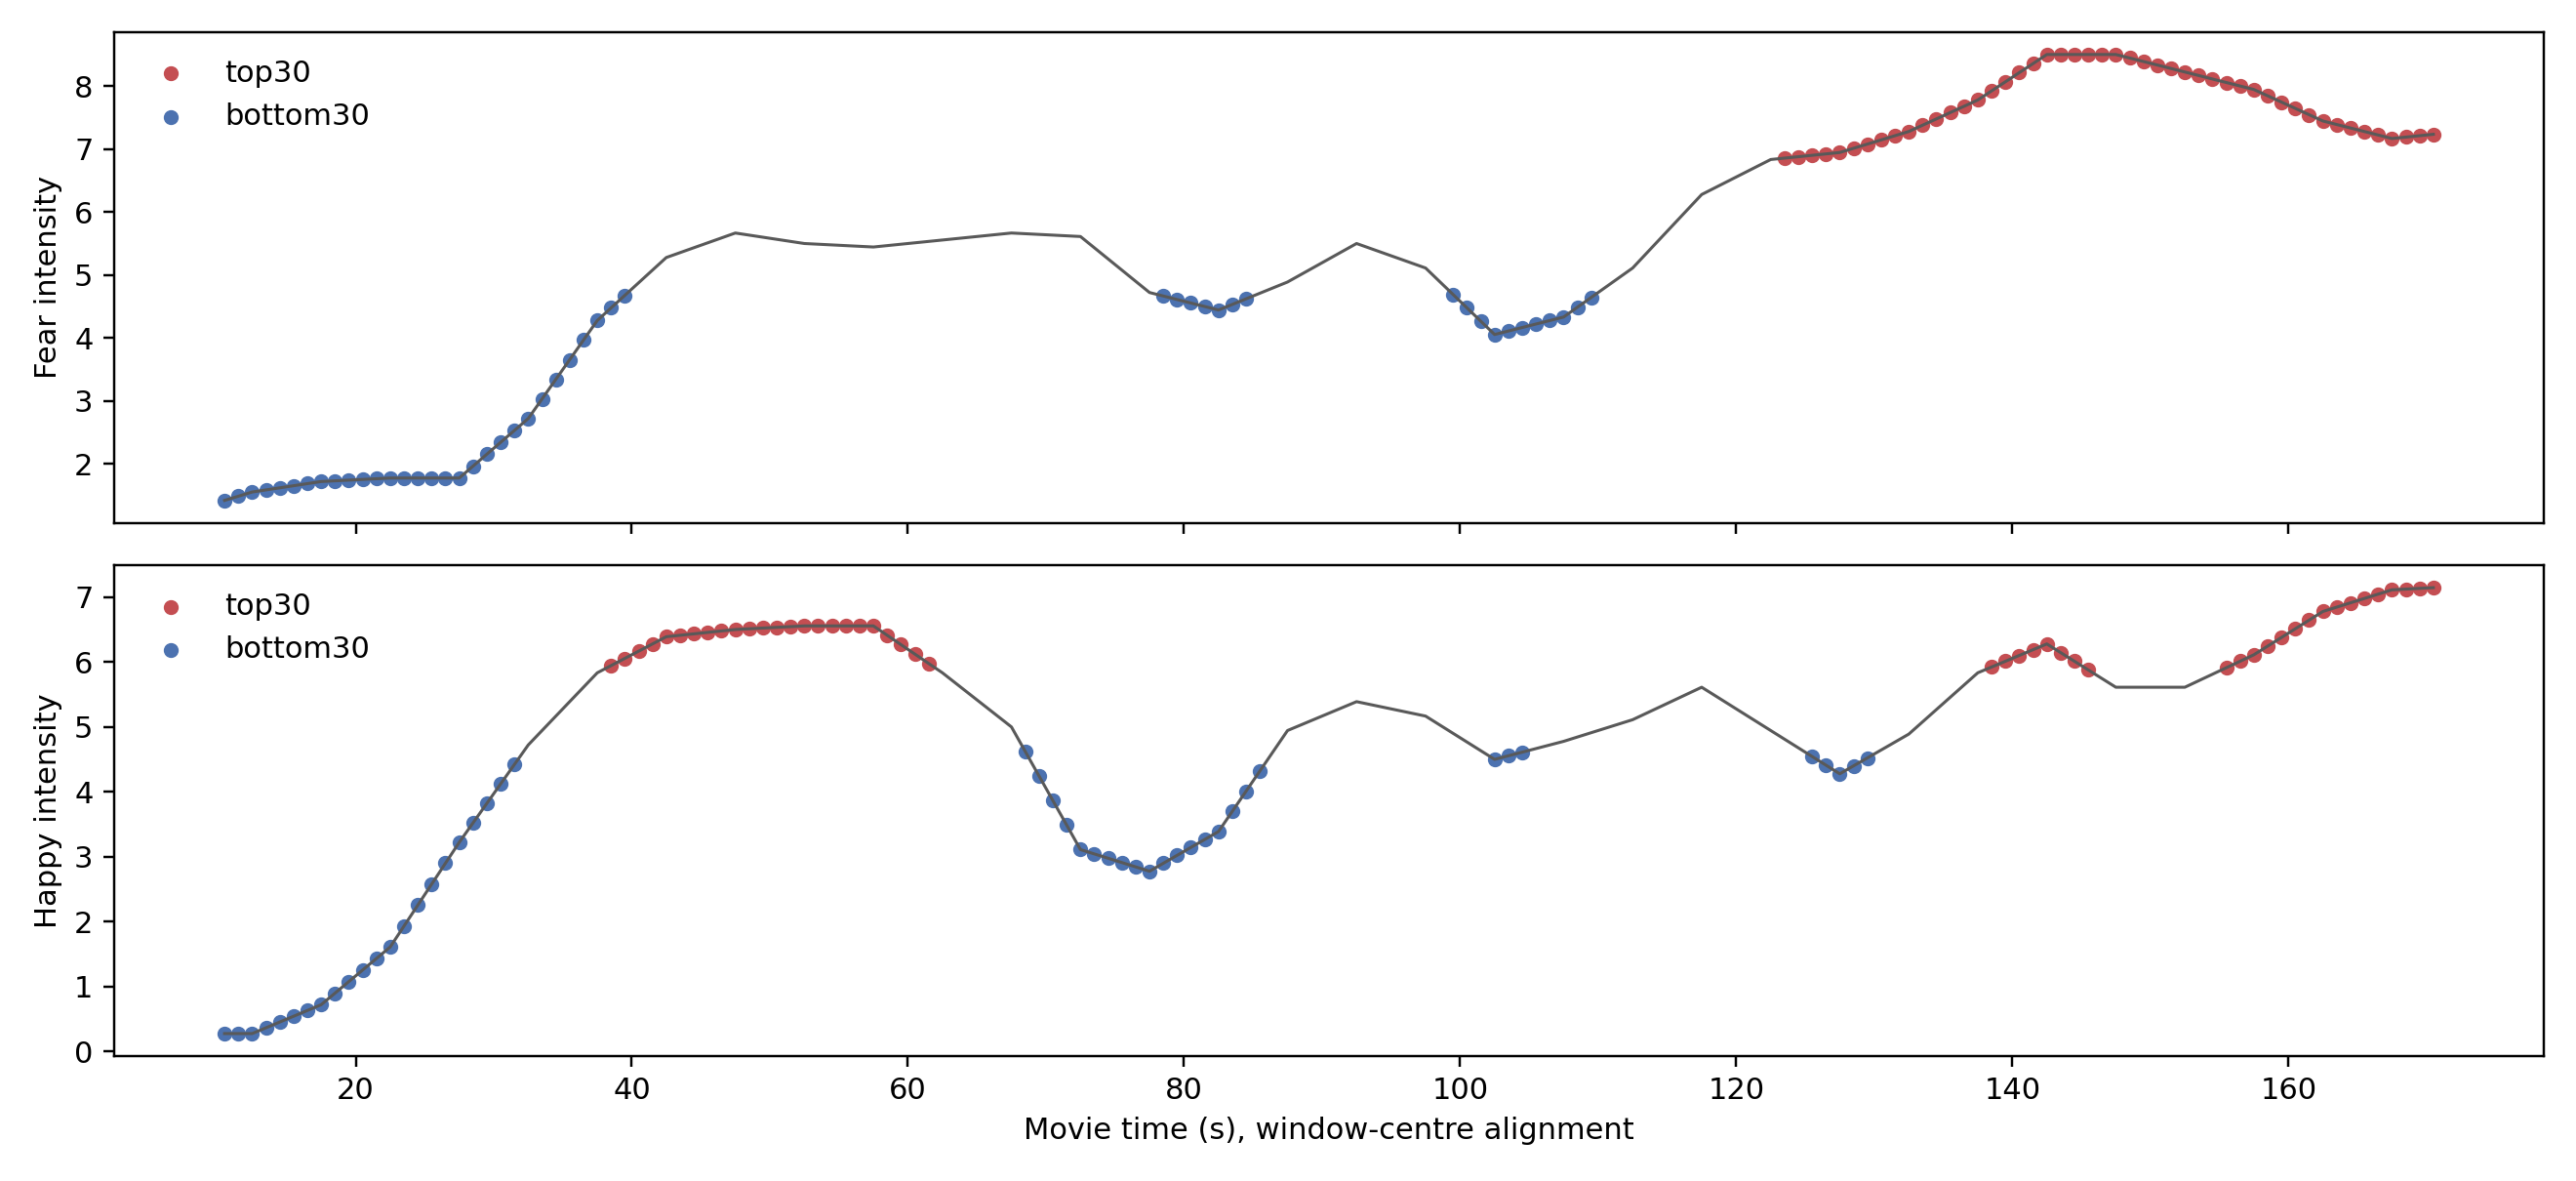

In [15]:
with LOG.step("Intensity epoch selection"):
    if True:
        selection_file = PATHS.intensity_results / "ra_selected_epochs.csv"
        figure_s5 = PATHS.supplementary / "Figure_S5_intensity_epochs.png"
        if not saved([selection_file, PATHS.intensity_results / "smoothed_intensity.csv",
                      PATHS.intensity_results / "analysis_parameters.json", figure_s5],
                     "Intensity epochs", inputs=[RATINGS_FILE]):
            run_script("preparation/select_intensity_epochs.py", ["--ratings", RATINGS_FILE])
            run_script("plotting/plot_figure_s5_intensity_epochs.py")
        selection = pd.read_csv(selection_file)
        overview = (selection.groupby(["emotion", "level"])
                    .agg(epochs=("ra_window_start", "size"), first_start_s=("dbhi_epoch_start_s", "min"),
                         last_start_s=("dbhi_epoch_start_s", "max"), mean_rating=("smoothed_ra_score", "mean"))
                    .reset_index())
        display(overview.style.hide(axis="index").format({"first_start_s": "{:.1f}", "last_start_s": "{:.1f}", "mean_rating": "{:.2f}"}))
        LOG.write("Selected epochs: " + "; ".join(f"{r.emotion}/{r.level} {r.epochs}" for r in overview.itertuples()))
        helpers.show_figure(figure_s5, width=900)

## 8. Age branch: ridge age models

The first prompt asks whether to run this branch (steps 8–10).

**Features.** For each direction and movie (four models), each child's feature
vector is the mean log10 index during the 48 high-intensity seconds at every
electrode: 4 EEG bands × 2 HRV bands × 63 electrodes = **504 features**, ordered
band → HRV band → electrode, with no spatial averaging.

**Model** (ridge regression of age in months)

| Setting | Value |
|---|---|
| Scaling | standardised inside each training fold |
| Penalty | `RidgeCV`, 25 log-spaced values from 10⁻² to 10⁴, internal leave-one-out |
| Cross-validation | 10-fold, repeated five times, predictions averaged |
| Performance | Pearson r between predicted and actual age; MAE exported in years |
| Significance | 1,000 permutations of the age labels, seed 0 |

**Retained limitation.** Each label permutation uses a single CV repeat, whereas
the observed statistic averages five repeats. Both counts are saved in
`analysis_parameters.json`; report the p values with that qualification.

About half a minute per model.

| Intermediate file under `05_dBHI/cache/age_prediction/` | Contents |
|---|---|
| `subjects_n148.csv`, `features_electrode_top30.npz` | IDs, ages and the four 148 × 504 feature matrices |
| `model_results.csv`, `oos_predictions.csv`, `null_distributions.npz` | r, permutation p and MAE per model; held-out predictions; label-permutation nulls |
| `analysis_parameters.json` | CV scheme, penalties, transform settings, input hashes |

In [17]:
with LOG.step("Age ridge models"):
    RUN_AGE = cache_policy.choose_branch("age", "8-10", log=LOG)
    if not RUN_AGE:
        print("Skipped: age branch not selected.")
    else:
        age_files = [PATHS.age_results / name for name in
                     ("subjects_n148.csv", "features_electrode_top30.npz", "model_results.csv",
                      "oos_predictions.csv", "null_distributions.npz", "analysis_parameters.json")]
        if not saved(age_files, "Age ridge models", inputs=[PATHS.intensity_results / "ra_selected_epochs.csv", MANIFEST_FILE, INFO_FILE]):
            run_script("analysis/predict_age_with_ridge.py", CACHE_ARGS)
        model_results = helpers.show_table(PATHS.age_results / "model_results.csv",
                                           formats={"r_oos": "{:.3f}", "perm_p": "{:.3f}", "mae_yr": "{:.2f}"},
                                           title="Out-of-sample age prediction (r, permutation p, MAE in years)")
        LOG.write("Age models: " + "; ".join(f"{r.model} r={r.r_oos:.2f} p={r.perm_p:.3f}" for r in model_results.itertuples()))

Run the age branch (steps 8-10)?
1 = yes (default)
2 = skip


Type 1 or 2, then press Enter (Enter alone = 1):  1


Age ridge models: recomputing and replacing saved results.
{'model': 'bth fear', 'n_features': 504, 'r_oos': np.float64(0.2604545291459886), 'perm_p': np.float64(0.001998001998001998), 'mae_yr': np.float64(1.371297607520839)}
{'model': 'bth happy', 'n_features': 504, 'r_oos': np.float64(0.14599791183909544), 'perm_p': np.float64(0.030969030969030968), 'mae_yr': np.float64(1.4177658629544316)}
{'model': 'htb fear', 'n_features': 504, 'r_oos': np.float64(0.2590509768711866), 'perm_p': np.float64(0.003996003996003996), 'mae_yr': np.float64(1.367518770730916)}
{'model': 'htb happy', 'n_features': 504, 'r_oos': np.float64(0.17129172423691796), 'perm_p': np.float64(0.015984015984015984), 'mae_yr': np.float64(1.400333727316548)}


**Out-of-sample age prediction (r, permutation p, MAE in years)**

model,n_features,r_oos,perm_p,mae_yr
bth fear,504,0.260,0.002,1.37
bth happy,504,0.146,0.031,1.42
htb fear,504,0.259,0.004,1.37
htb happy,504,0.171,0.016,1.40


## 9. Age branch: child-centred models and Haufe patterns

**Centred models.** Every child's 504 features are centred on their own mean, which
removes the overall coupling level and keeps the spatial pattern. The four ridge
models are refitted with the same CV and permutation scheme (and the same retained
limitation).

**Haufe patterns** (Haufe et al., 2014)

- From the full-sample ridge fit of each centred model: the covariance between each
  feature and the model's prediction, divided by the prediction variance.
- Interpretable as the direction of the age-related signal, not as a weight.
- Uncertainty: **1,000 participant bootstraps** (seed 1) with the penalty fixed at
  its full-sample value; pointwise 95% intervals, not corrected across features.

| Intermediate file under `05_dBHI/cache/age_prediction/` | Contents |
|---|---|
| `haufe_patterns_{direction}_{movie}.csv` | pattern value and bootstrap CI per feature |
| `haufe_bootstrap_{direction}_{movie}.npz` | bootstrap patterns, centred-model nulls, weights |
| `haufe_parameters.json` | centred-model r, p and MAE; penalty; number of features whose CI excludes 0 |

In [19]:
with LOG.step("Centred models and Haufe patterns"):
    if not RUN_AGE:
        print("Skipped: age branch not selected in step 8.")
    else:
        tags = ["bth_fear", "bth_happy", "htb_fear", "htb_happy"]
        haufe_files = [PATHS.age_results / f"haufe_patterns_{t}.csv" for t in tags]
        haufe_files += [PATHS.age_results / f"haufe_bootstrap_{t}.npz" for t in tags] + [PATHS.age_results / "haufe_parameters.json"]
        if not saved(haufe_files, "Haufe patterns", inputs=[PATHS.age_results / "model_results.csv", PATHS.age_results / "features_electrode_top30.npz"]):
            run_script("analysis/compute_haufe_patterns.py")
        haufe = json.loads((PATHS.age_results / "haufe_parameters.json").read_text())["models"]
        haufe_summary = pd.DataFrame([{"model": name, **values} for name, values in haufe.items()])
        display(haufe_summary.style.hide(axis="index").format({"r_cv_raw": "{:.3f}", "r_cv_centred": "{:.3f}", "perm_p_centred": "{:.3f}",
                                                               "mae_centred_yr": "{:.2f}", "lambda_full": "{:.3g}"}))
        LOG.write("Centred models: " + "; ".join(f"{r.model} r={r.r_cv_centred:.2f} p={r.perm_p_centred:.3f} CI≠0 {r.n_ci_excl0}" for r in haufe_summary.itertuples()))

Haufe patterns: recomputing and replacing saved results.
bth fear {"r_cv_raw": 0.2604545291459886, "r_cv_centred": 0.27466308727172745, "perm_p_centred": 0.001998001998001998, "mae_centred_yr": 1.369710533967053, "lambda_full": 1000.0, "n_ci_excl0": 60}
bth happy {"r_cv_raw": 0.1459979118390954, "r_cv_centred": 0.08333122587108033, "perm_p_centred": 0.07292707292707293, "mae_centred_yr": 1.4388033871692538, "lambda_full": 3162.2776601683795, "n_ci_excl0": 54}
htb fear {"r_cv_raw": 0.2590509768711866, "r_cv_centred": 0.23527613541751502, "perm_p_centred": 0.002997002997002997, "mae_centred_yr": 1.3859640247681215, "lambda_full": 1000.0, "n_ci_excl0": 62}
htb happy {"r_cv_raw": 0.1712917242369179, "r_cv_centred": 0.179547251639258, "perm_p_centred": 0.015984015984015984, "mae_centred_yr": 1.4016648474861693, "lambda_full": 1000.0, "n_ci_excl0": 24}


model,r_cv_raw,r_cv_centred,perm_p_centred,mae_centred_yr,lambda_full,n_ci_excl0
bth fear,0.260,0.275,0.002,1.37,1e+03,60
bth happy,0.146,0.083,0.073,1.44,3.16e+03,54
htb fear,0.259,0.235,0.003,1.39,1e+03,62
htb happy,0.171,0.180,0.016,1.40,1e+03,24


## 10. Age branch: Figure 4 and Table S5

- **Figure 4:** Haufe patterns of the centred models as scalp maps per EEG band and
  HRV band; dots mark electrodes whose bootstrap interval excludes zero; the
  modulation averaged over the marked electrodes of selected clusters is plotted
  against age. Those trajectories use the same data that selected the electrodes,
  so they are descriptive.
- **Table S5:** r, permutation p and MAE for the main and centred models, and the
  number of features with intervals excluding zero.

| Final output | Location |
|---|---|
| `Figure_4_age_prediction.png` | `results/Main/` |
| `Table_S5_age_prediction.csv` | `results/SI/` |

Figure 4 and Table S5: recomputing and replacing saved results.
Saved: results/Main/Figure_4_age_prediction.png
     Direction    Movie  Features     r      p MAE (years) r (centred) p (centred) MAE (centred, years)  Features with CI excluding 0
0  Brain→Heart  Fearful       504  0.26  0.002        1.37        0.27       0.002                 1.37                            60
1  Brain→Heart    Happy       504  0.15  0.031        1.42        0.08       0.073                 1.44                            54
2  Heart→Brain  Fearful       504  0.26  0.004        1.37        0.24       0.003                 1.39                            62
3  Heart→Brain    Happy       504  0.17  0.016        1.40        0.18       0.016                 1.40                            24


**Table S5. Age prediction from directional modulation**

Direction,Movie,Features,r,p,MAE (years),r (centred),p (centred),"MAE (centred, years)",Features with CI excluding 0
Brain→Heart,Fearful,504,0.260000,0.002000,1.370000,0.270000,0.002000,1.370000,60
Brain→Heart,Happy,504,0.150000,0.031000,1.420000,0.080000,0.073000,1.440000,54
Heart→Brain,Fearful,504,0.260000,0.004000,1.370000,0.240000,0.003000,1.390000,62
Heart→Brain,Happy,504,0.170000,0.016000,1.400000,0.180000,0.016000,1.400000,24


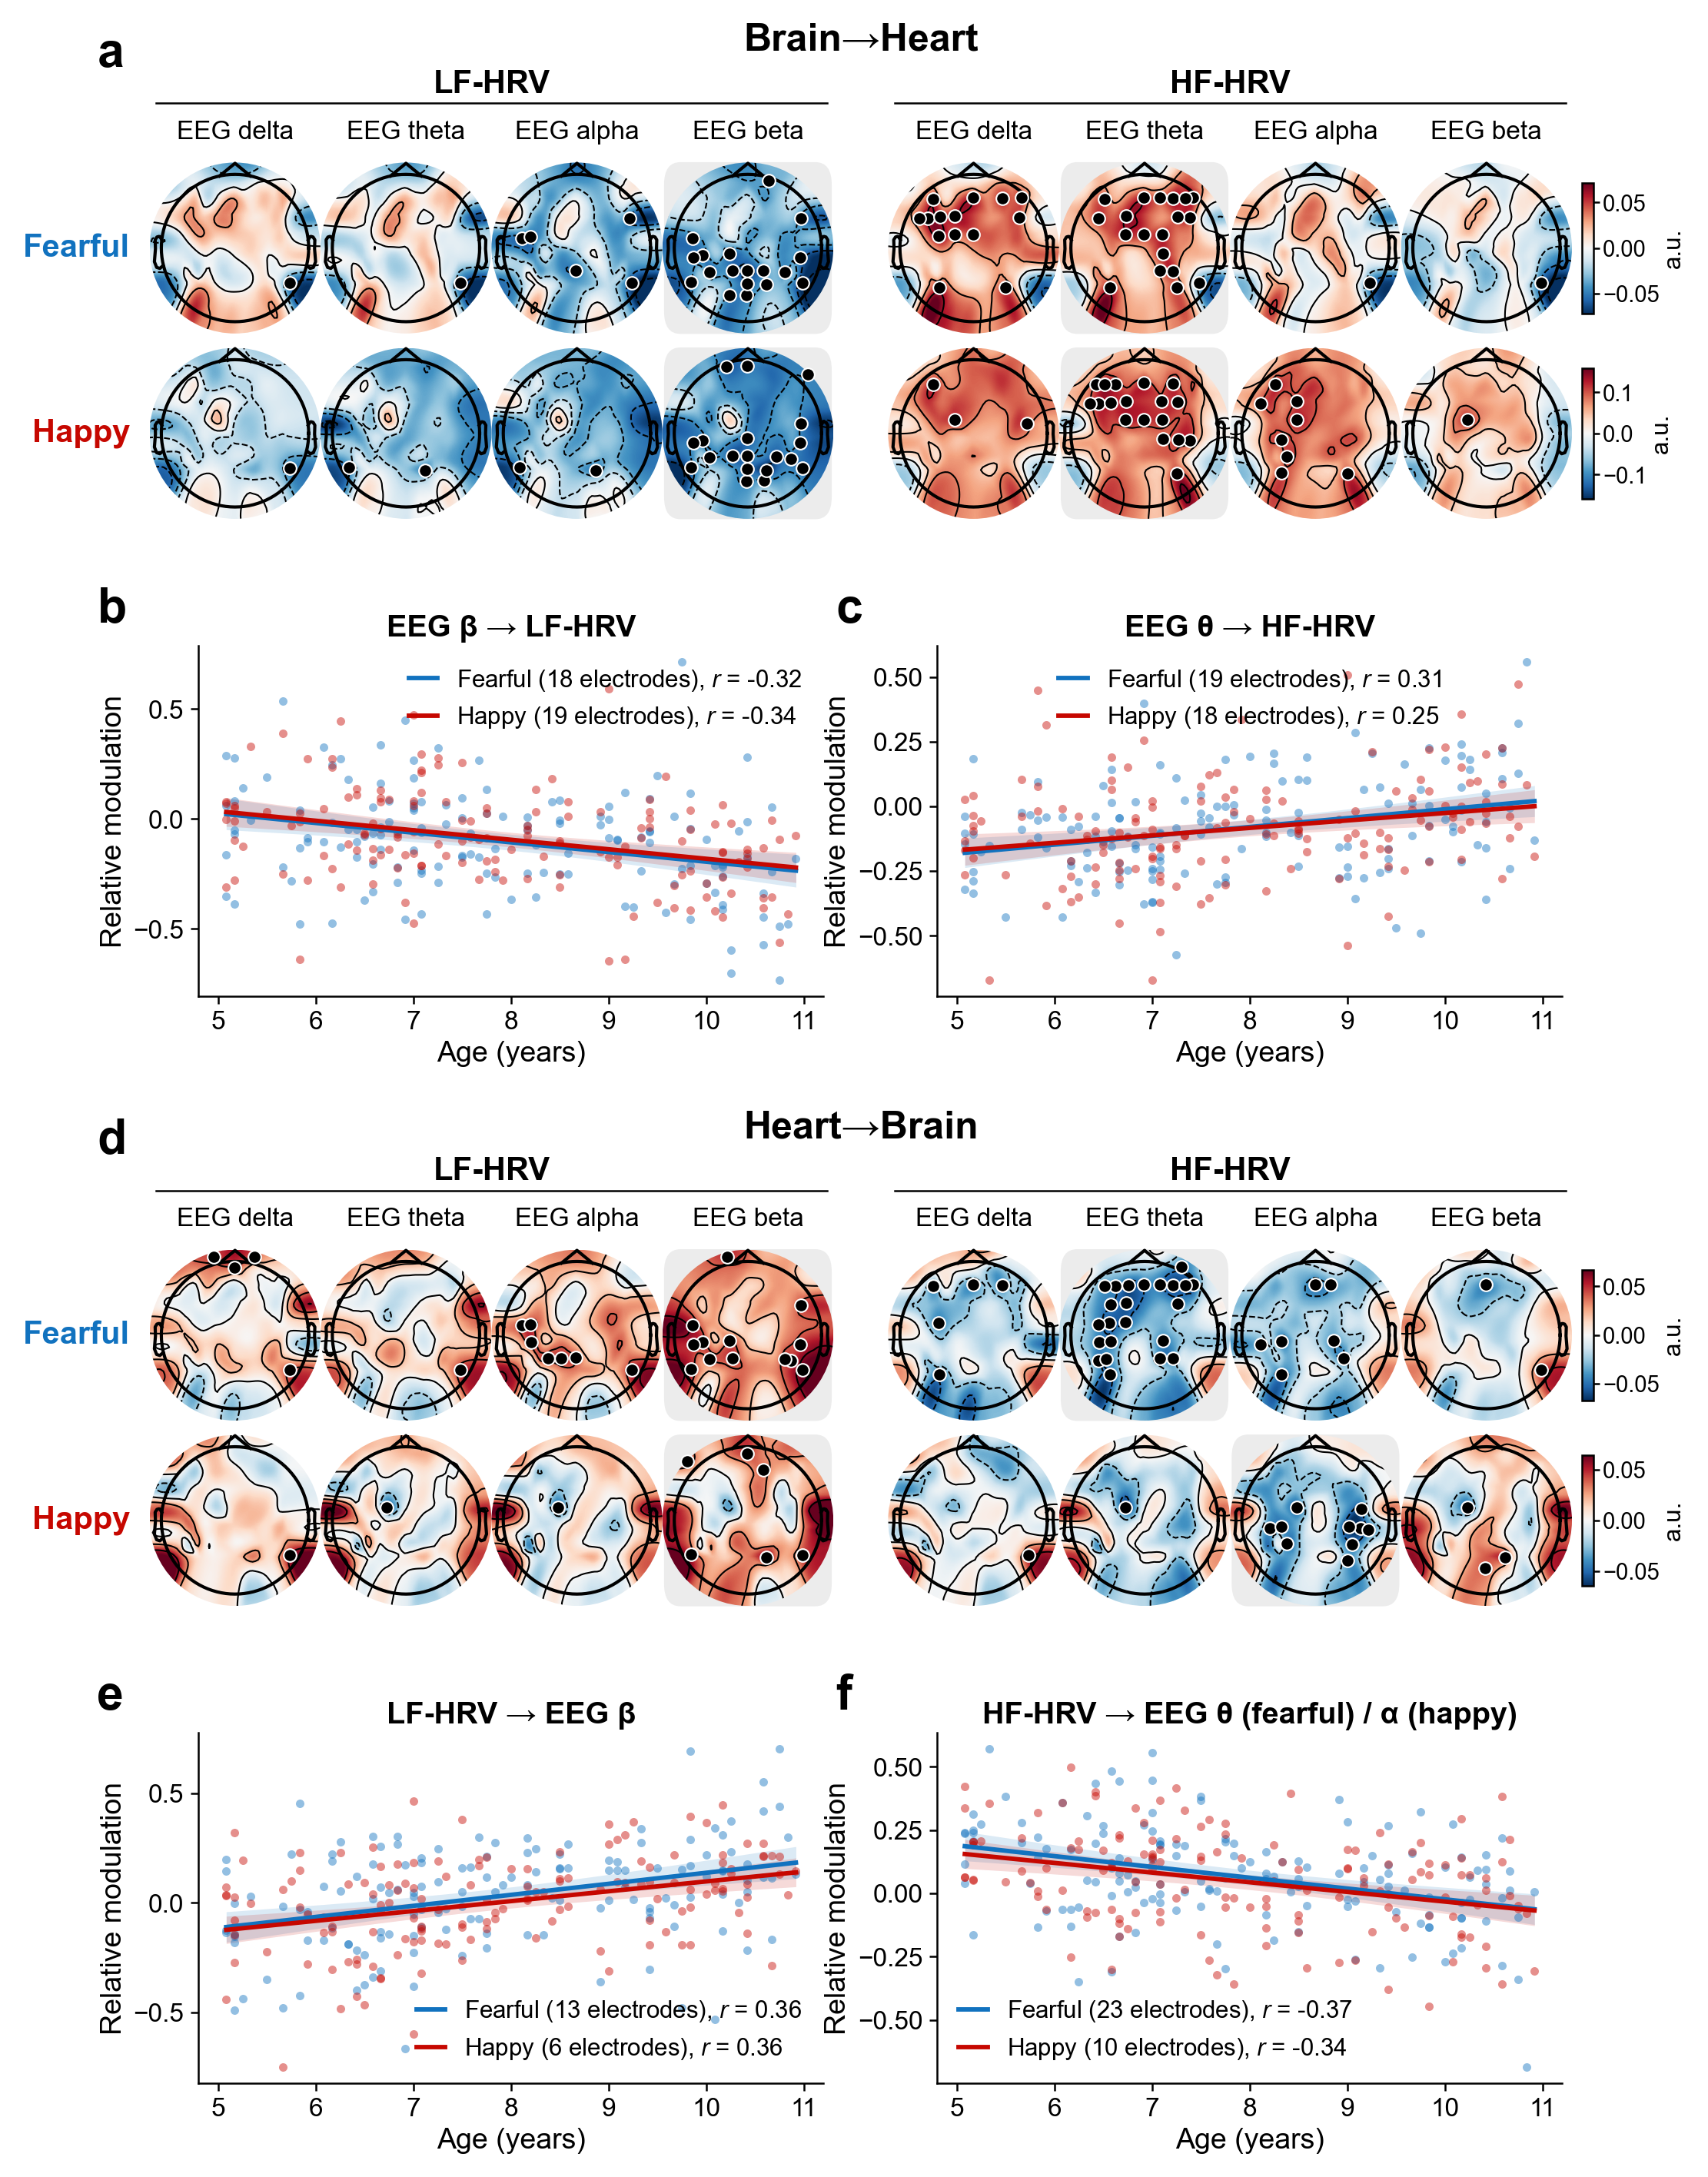

Figures: results/Main | results/SI
Run log: 05_dBHI/logs/20261030_225036.log


In [21]:
with LOG.step("Figure 4 and Table S5"):
    if not RUN_AGE:
        print("Skipped: age branch not selected in step 8.")
    else:
        figure_4 = PATHS.figures / "Figure_4_age_prediction.png"
        table_s5 = PATHS.supplementary / "Table_S5_age_prediction.csv"
        if not saved([figure_4, table_s5], "Figure 4 and Table S5",
                     inputs=[PATHS.age_results / "haufe_parameters.json", PATHS.age_results / "model_results.csv"]):
            run_script("plotting/plot_figure_4_age_prediction.py")
            run_script("analysis/export_table_s5_age_prediction.py")
        helpers.show_table(table_s5, title="Table S5. Age prediction from directional modulation")
        helpers.show_figure(figure_4, width=1000)
        LOG.write(f"Figure 4: {shown(figure_4)}; Table S5: {shown(table_s5)}")

print("Figures:", shown(PATHS.figures), "|", shown(PATHS.supplementary))
print("Run log:", shown(LOG.path))

## 11. Intensity branch: high-minus-low intensity contrasts

The first prompt asks whether to run this branch (steps 11–13).

For each child, movie, direction, EEG band, HRV band and electrode:

- average the log10 index over the 48 high-intensity seconds and over the 48
  low-intensity seconds selected in step 7;
- take the difference.

Only the fearful and happy clips are used, so the neutral truncation of `sub-047`
plays no role here. The result is one array per movie and direction of shape
148 × 4 bands × 2 HRV bands × 63 electrodes, all finite.

| Intermediate file under `05_dBHI/cache/intensity_contrast/` | Contents |
|---|---|
| `topo_subject_channel_diff.npz` | the four contrast arrays with IDs, groups, labels and band names |
| `contrast_parameters.json` | input hashes and transform settings |

In [23]:
with LOG.step("Intensity contrasts"):
    RUN_INTENSITY = cache_policy.choose_branch("intensity", "11-13", log=LOG)
    if not RUN_INTENSITY:
        print("Skipped: intensity branch not selected.")
    else:
        contrast_file = PATHS.intensity_results / "topo_subject_channel_diff.npz"
        if not saved([contrast_file, PATHS.intensity_results / "contrast_parameters.json"], "Intensity contrasts",
                     inputs=[PATHS.intensity_results / "ra_selected_epochs.csv", MANIFEST_FILE, INFO_FILE]):
            run_script("analysis/compute_intensity_contrasts.py", CACHE_ARGS)
        with np.load(contrast_file, allow_pickle=False) as contrasts:
            shapes = {key: contrasts[key].shape for key in contrasts.files if "__" in key}
            counts = pd.Series(contrasts["groups"]).value_counts().to_dict()
        display(pd.DataFrame([{"Array": k, "Shape (children × EEG bands × HRV bands × electrodes)": " × ".join(map(str, v))}
                              for k, v in shapes.items()]).style.hide(axis="index"))
        print("Children per age group:", counts)
        LOG.write(f"Contrast arrays: {list(shapes)}; groups {counts}")

Run the intensity branch (steps 11-13)?
1 = yes (default)
2 = skip


Type 1 or 2, then press Enter (Enter alone = 1):  1


Intensity contrasts: recomputing and replacing saved results.
{'5-6 yrs': 50, '9-10 yrs': 49, '7-8 yrs': 49}


Array,Shape (children × EEG bands × HRV bands × electrodes)
fear__htb,148 × 4 × 2 × 63
fear__bth,148 × 4 × 2 × 63
happy__htb,148 × 4 × 2 × 63
happy__bth,148 × 4 × 2 × 63


Children per age group: {'5-6 yrs': 50, '9-10 yrs': 49, '7-8 yrs': 49}


## 12. Intensity branch: spatial cluster tests

Each contrast map is tested against zero across the 63 electrodes within its age
group, with MNE's one-sample cluster permutation test.

| Setting | Value |
|---|---|
| Maps | 96 = 2 movies × 2 directions × 4 EEG bands × 2 HRV bands × 3 groups |
| Cluster-forming threshold | two-sided t, p < .05; minimum cluster size one electrode |
| Cluster mass | summed t; null = maximum absolute cluster mass |
| Permutations | **10,000**, seed 20260928; maps without a supra-threshold electrode skip them |
| Adjacency | Delaunay triangulation of the standard-1020 montage; the hull shortcuts F9–P9 and F10–P10 removed because they join non-neighbouring electrodes |
| Correction | within each map; none across the 96 maps |

Progress is printed per map (about a minute in total). The significant clusters
and the adjacency diagnostic are displayed.

| Intermediate file under `05_dBHI/cache/intensity_contrast/topo_cluster/` | Contents |
|---|---|
| `topo_channel_tests.csv` | per-map, per-electrode mean, t, uncorrected p and cluster membership |
| `topo_clusters.csv`, `topo_map_summary.csv` | every cluster with mass and p; per-map counts |
| `cluster_null_distributions.npz` | the permutation null of each map |
| `channel_adjacency.npz`, `channel_adjacency_edges.csv`, `channel_adjacency.png` | the adjacency graph and its diagnostic image |
| `analysis_parameters.json` | settings, package versions and the source hash |

Spatial clusters: recomputing and replacing saved results.
Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 63
Loaded 148 participants; 50/49/49 per group; 63 channels; 175 adjacency edges.
01/96 fear bth 5-6 yrs delta-LF: 1 significant clusters
02/96 fear bth 5-6 yrs delta-HF: 0 significant clusters
03/96 fear bth 5-6 yrs theta-LF: 1 significant clusters
04/96 fear bth 5-6 yrs theta-HF: 0 significant clusters
05/96 fear bth 5-6 yrs alpha-LF: 1 significant clusters
06/96 fear bth 5-6 yrs alpha-HF: 0 significant clusters
07/96 fear bth 5-6 yrs beta-LF: 1 significant clusters
08/96 fear bth 5-6 yrs beta-HF: 1 significant clusters
09/96 fear bth 7-8 yrs delta-LF: 1 significant clusters
10/96 fear bth 7-8 yrs delta-HF: 0 significant clusters
11/96 fear bth 7-8 yrs theta-LF: 0 significant clusters
12/96 fear bth 7-8 yrs theta-HF: 0 significant clusters
13/96 fear bth 7-8 yrs alpha-LF: 0 significant cluster

emotion,direction,group,band,hrv,n,sign,n_channels,t_mass,p_cluster
fear,bth,5-6 yrs,delta,LF,50,positive,62,186.4,0.0022
fear,bth,5-6 yrs,theta,LF,50,positive,61,191.1,0.0023
fear,bth,5-6 yrs,alpha,LF,50,positive,46,126.4,0.0158
fear,bth,5-6 yrs,beta,LF,50,positive,21,54.6,0.0380
fear,bth,5-6 yrs,beta,HF,50,negative,34,-98.9,0.0229
fear,bth,7-8 yrs,delta,LF,49,positive,45,111.8,0.0188
fear,bth,7-8 yrs,beta,HF,49,negative,47,-143.8,0.0087
fear,bth,9-10 yrs,delta,LF,49,positive,21,48.2,0.0364
fear,bth,9-10 yrs,delta,LF,49,positive,14,30.8,0.0478
fear,htb,5-6 yrs,alpha,HF,50,positive,8,21.7,0.0286


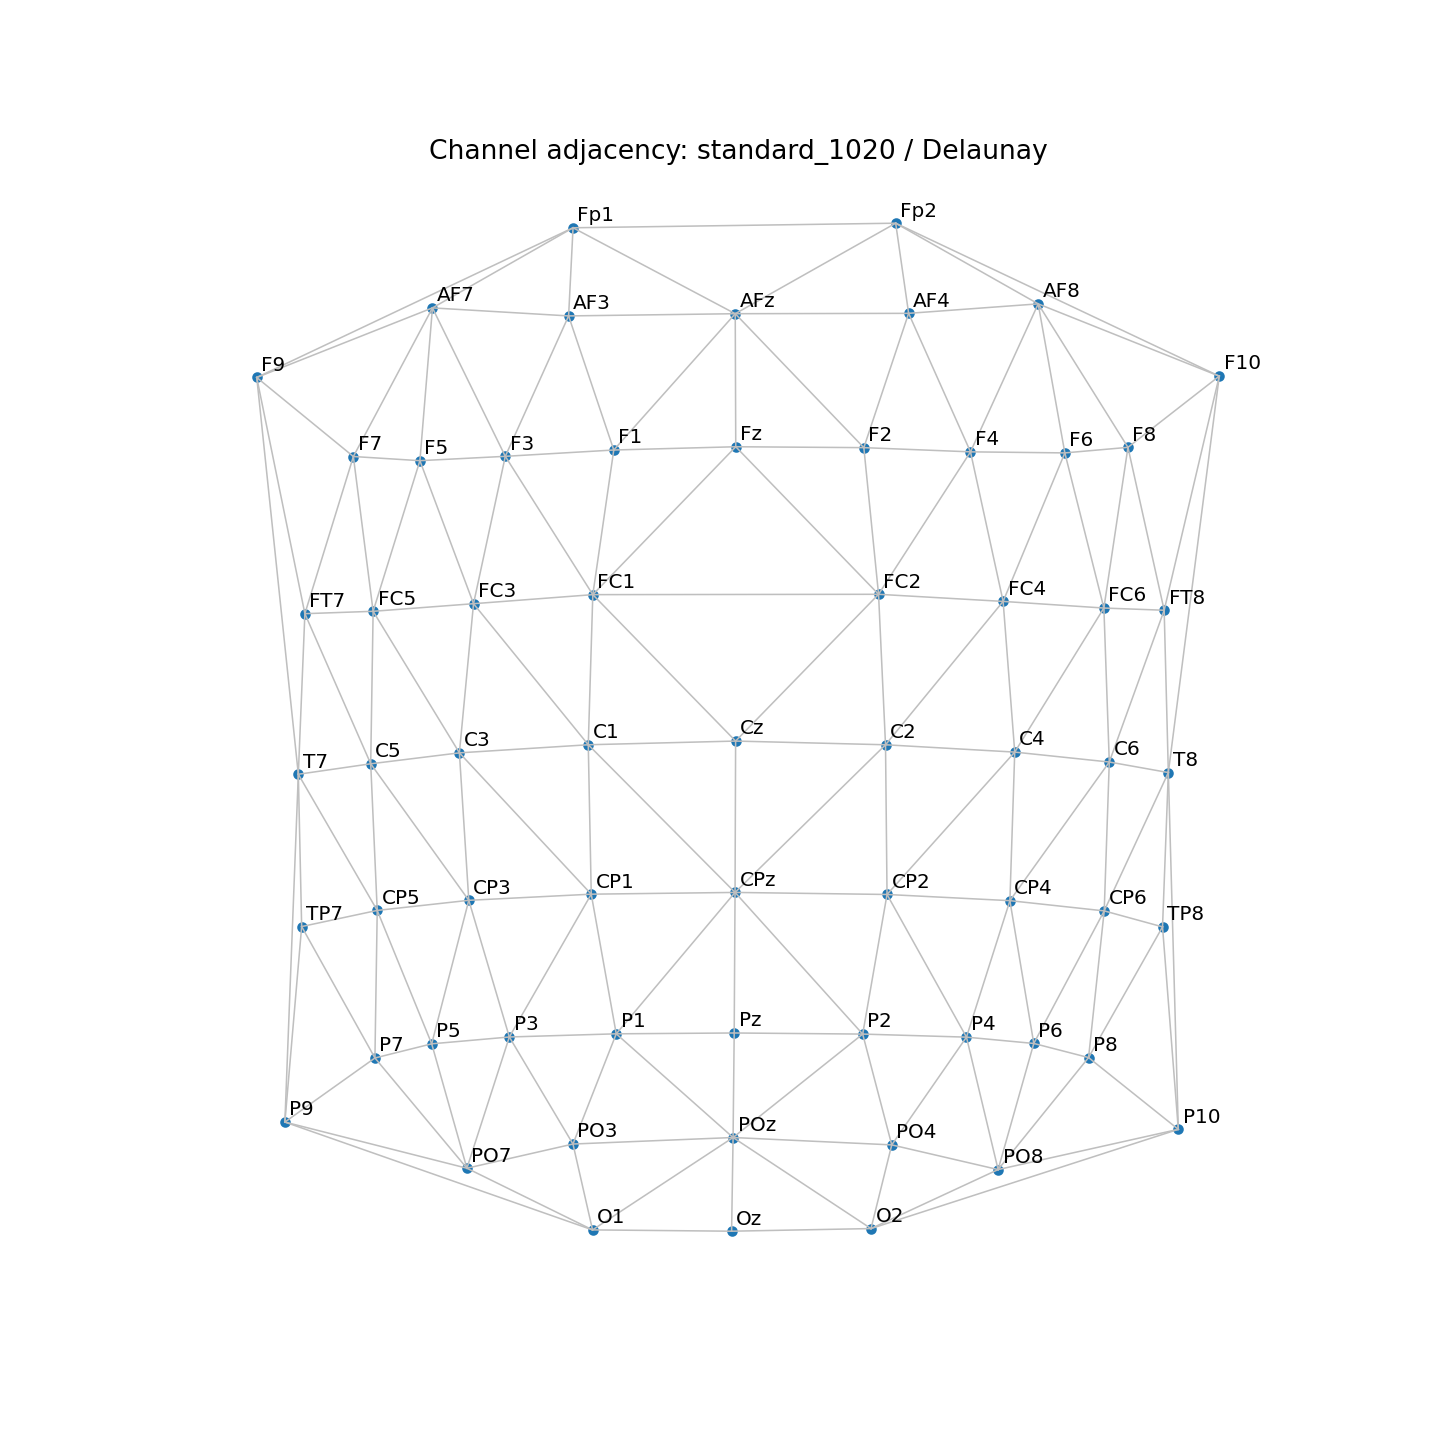

In [25]:
with LOG.step("Spatial clusters"):
    if not RUN_INTENSITY:
        print("Skipped: intensity branch not selected in step 11.")
    else:
        spatial_files = [PATHS.spatial_results / name for name in
                         ("topo_channel_tests.csv", "topo_clusters.csv", "topo_map_summary.csv",
                          "cluster_null_distributions.npz", "analysis_parameters.json", "channel_adjacency.png")]
        if not saved(spatial_files, "Spatial clusters", inputs=[PATHS.intensity_results / "topo_subject_channel_diff.npz"]):
            run_script("analysis/analyze_intensity_spatial_clusters.py")
        spatial_clusters = pd.read_csv(PATHS.spatial_results / "topo_clusters.csv")
        map_summary = pd.read_csv(PATHS.spatial_results / "topo_map_summary.csv")
        significant_spatial = spatial_clusters.loc[spatial_clusters.significant]
        print(f"Significant clusters: {len(significant_spatial)} in {int((map_summary.n_significant_clusters > 0).sum())} of {len(map_summary)} maps")
        display(significant_spatial[["emotion", "direction", "group", "band", "hrv", "n", "sign", "n_channels", "t_mass", "p_cluster"]]
                .style.hide(axis="index").format({"t_mass": "{:.1f}", "p_cluster": "{:.4f}"}))
        helpers.show_figure(PATHS.spatial_results / "channel_adjacency.png", width=420)
        LOG.write(f"Spatial clusters: {len(significant_spatial)} significant over {len(map_summary)} maps")

## 13. Intensity branch: Figure 5, Figures S6–S7 and Table S6

- **Figure 5:** delta-band contrast maps (group means of high minus low intensity)
  for both movies, directions and HRV bands; dots mark electrodes in a significant
  cluster.
- **Figures S6 (fearful) and S7 (happy):** all four EEG bands; within each
  direction × HRV band × EEG band × movie panel the three age groups share one
  symmetric colour scale.
- **Table S6:** significant clusters with electrode counts, masses and p values.

All read the saved tests from step 12.

| Final output | Location |
|---|---|
| `Figure_5_intensity_contrasts.png` | `results/Main/` |
| `Figure_S6_intensity_contrasts_fear.png`, `Figure_S7_intensity_contrasts_happy.png` | `results/SI/` |
| `Table_S6_intensity_clusters.csv` | `results/SI/` |

Figure 5, Figures S6-S7 and Table S6: recomputing and replacing saved results.
Saved: results/Main/Figure_5_intensity_contrasts.png
Saved: results/SI/Figure_S6_intensity_contrasts_fear.png
Saved: results/SI/Figure_S7_intensity_contrasts_happy.png
       Movie    Direction Age group   n EEG band HRV band  Electrodes      Effect  Cluster mass (sum t) Cluster p
2    Fearful  Brain→Heart       5-6  50    alpha       LF          46  high > low                 126.4     0.016
5    Fearful  Brain→Heart       5-6  50     beta       HF          34  high < low                 -98.9     0.023
4    Fearful  Brain→Heart       5-6  50     beta       LF          21  high > low                  54.6     0.038
0    Fearful  Brain→Heart       5-6  50    delta       LF          62  high > low                 186.4     0.002
1    Fearful  Brain→Heart       5-6  50    theta       LF          61  high > low                 191.1     0.002
20   Fearful  Brain→Heart       7-8  49     beta       HF          47

**Table S6. Significant spatial intensity-contrast clusters**

Movie,Direction,Age group,n,EEG band,HRV band,Electrodes,Effect,Cluster mass (sum t),Cluster p
Fearful,Brain→Heart,5-6,50,alpha,LF,46,high > low,126.400000,0.016
Fearful,Brain→Heart,5-6,50,beta,HF,34,high < low,-98.900000,0.023
Fearful,Brain→Heart,5-6,50,beta,LF,21,high > low,54.600000,0.038
Fearful,Brain→Heart,5-6,50,delta,LF,62,high > low,186.400000,0.002
Fearful,Brain→Heart,5-6,50,theta,LF,61,high > low,191.100000,0.002
Fearful,Brain→Heart,7-8,49,beta,HF,47,high < low,-143.800000,0.009
Fearful,Brain→Heart,7-8,49,delta,LF,45,high > low,111.800000,0.019
Fearful,Brain→Heart,9-10,49,delta,LF,21,high > low,48.200000,0.036
Fearful,Brain→Heart,9-10,49,delta,LF,14,high > low,30.800000,0.048
Fearful,Heart→Brain,5-6,50,alpha,HF,8,high > low,21.700000,0.029


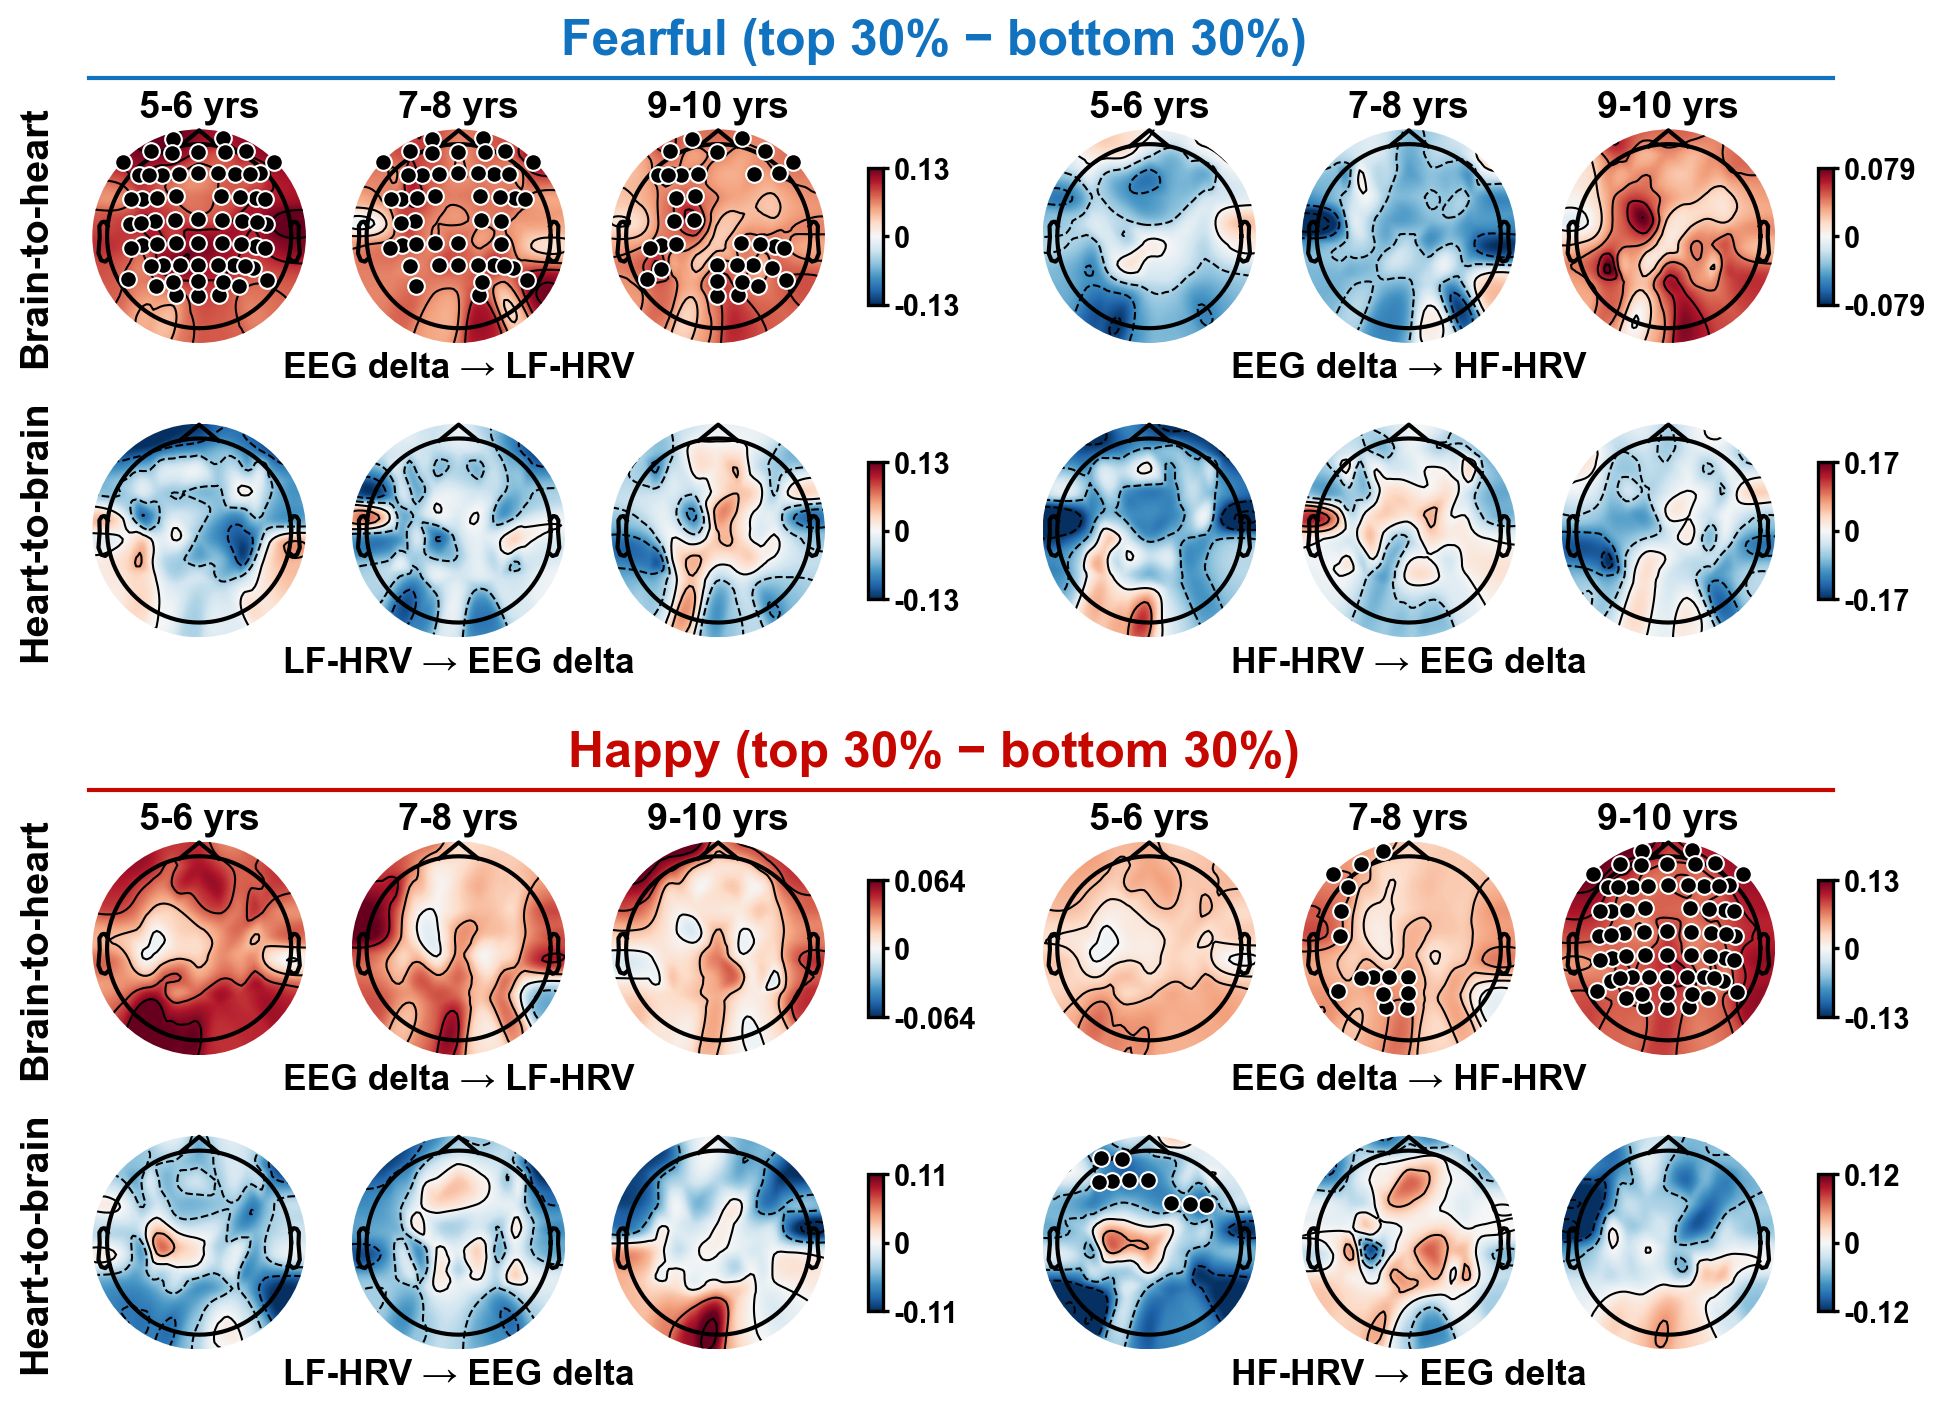

In [27]:
with LOG.step("Figure 5, Figures S6-S7 and Table S6"):
    if not RUN_INTENSITY:
        print("Skipped: intensity branch not selected in step 11.")
    else:
        figure_5 = PATHS.figures / "Figure_5_intensity_contrasts.png"
        figures_s6_s7 = [PATHS.supplementary / "Figure_S6_intensity_contrasts_fear.png",
                         PATHS.supplementary / "Figure_S7_intensity_contrasts_happy.png"]
        table_s6 = PATHS.supplementary / "Table_S6_intensity_clusters.csv"
        if not saved([figure_5, *figures_s6_s7, table_s6], "Figure 5, Figures S6-S7 and Table S6",
                     inputs=[PATHS.spatial_results / "topo_channel_tests.csv", PATHS.spatial_results / "topo_clusters.csv"]):
            run_script("plotting/plot_figure_5_intensity_contrasts.py")
            run_script("plotting/plot_figures_s6_s7_intensity_contrasts.py")
            run_script("analysis/export_table_s6_intensity_clusters.py")
        helpers.show_table(table_s6, title="Table S6. Significant spatial intensity-contrast clusters")
        helpers.show_figure(figure_5, width=1000)
        LOG.write(f"Figure 5: {shown(figure_5)}; Table S6 and Figures S6-S7: {shown(PATHS.supplementary)}")